# Home Credit Scorecard Model
### Business research, data understanding, validation design and EDA (Steps 1–3)

**Role:** Credit-risk data science for Home Credit Indonesia
**Data:** files provided for this project (Home Credit loan applications and credit-history tables). Their structure matches the public *Home Credit Default Risk* dataset, whose documentation (https://www.kaggle.com/competitions/home-credit-default-risk/data) is used only as a reference for context and column meanings.

This notebook covers only the stages completed so far. Later stages (EDA, feature engineering, modelling, business impact)
will be appended as new sections once each stage is validated.

**Ground rules followed in this notebook**
* Every statistic is computed from the actual files; nothing is assumed or typed in by hand.
* Large tables are streamed in chunks; the notebook never loads every file at once.
* Primary keys and table grain are treated as hypotheses and tested.
* No modelling happens here. The only artefact used later is the train/holdout/fold assignment, created at the end.

**Contents**
1. Step 1 — Business and subject-matter research
2. Step 2 — Environment and data acquisition
3. Step 2 — Streaming schema inspection of all eight tables
4. Step 2 — Keys, relationships and coverage
5. Step 2 — Target definition and class balance
6. Step 2 — Targeted data-quality investigations
7. Step 2 — Train vs scoring-set (`application_test`) differences
8. Step 2 — Validation design (locked holdout and CV folds)
9. Summary of findings and decisions (Steps 1–2)
10. Step 3 — Exploratory data analysis

## 1. Step 1 — Business and subject-matter research

**Objective.** Establish what the model predicts, how a prediction becomes a lending decision, and which validation standards apply.

### 1.1 Credit scoring
Hand and Henley (1997) describe credit scoring as formal statistical methods that classify credit applicants into
"good" and "bad" risk classes. Modern practice produces a continuous score or probability, and the lending decision is
taken separately by policy. This separation shapes the whole project.

### 1.2 What `TARGET` means
The official column description (verified in Section 5 below) defines `TARGET = 1` as a client with payment
difficulties: a late payment of more than X days on at least one of the first Y instalments of the loan. `TARGET = 0`
covers all other cases. **X and Y are not disclosed.** Consequences:
1. `TARGET` is an early-delinquency flag, not a regulatory default definition (for example Basel's 90 days past due).
   Model outputs are called *probability of payment difficulty*, not a Basel PD.
2. Expected-loss figures built on it are illustrative only. Many early-delinquent clients cure, so treating every
   `TARGET = 1` as a full loss would overstate losses.

### 1.3 Business mission and the cost of both errors
The public description of this dataset states that Home Credit aims to broaden financial inclusion for the unbanked, using
alternative data, and that it wants to avoid rejecting clients who are capable of repaying. False rejections are therefore an
explicit business cost.

| Error | Meaning | Approximate cost driver |
|---|---|---|
| False approval | A client with payment difficulties is approved | Exposure × loss rate, minus interest collected before delinquency |
| False rejection | A client who would repay is rejected | Forgone margin, relationship value, financial-inclusion objective |

The cost ratio is unknown for this dataset, so business impact (Step 10) will use clearly labelled sensitivity scenarios.

### 1.4 Risk ranking versus approval decision
The model ranks applicants. The **credit policy** turns the ranking into actions: cut-offs, manual-review bands, limits and
pricing. Basel validation guidance emphasises that validation covers both predictive ability and the *use* of ratings in
the credit process, with qualitative as well as quantitative components. Basel also separates a PD (an ex-ante estimate for an
obligor) from a default rate (an ex-post rate observed over a group). Comparing the two by score band is exactly what a
calibration check does.

### 1.5 Selection bias
The training data contains only loans that were **granted**; rejected applicants have no outcome. Reject inference
(Henley, 1995) attempts to reduce this bias, but the dataset contains no rejected population, so it cannot be done here.
Performance on the full through-the-door population may be worse than validation suggests. This is recorded as a deployment risk.

### 1.6 Why class imbalance matters
With a rare positive class, accuracy rewards predicting "no difficulty" for everyone, and ROC plots can look flattering.
Saito and Rehmsmeier (2015) show that precision–recall analysis is more informative on imbalanced data. PR-AUC is
therefore reported alongside ROC-AUC. Gini = 2 × ROC-AUC − 1 is reported for industry comparability.

### 1.7 Why probabilities must be validated before thresholds
A model can rank well yet produce badly scaled probabilities. Proper scoring rules such as the Brier score combine
calibration and discrimination, so a reliability diagram is reported alongside the Brier score. Calibrators must be fitted on data the model
has not seen (scikit-learn `CalibratedClassifierCV`). Class weighting and resampling deliberately distort probabilities, so
models trained that way must be recalibrated before their outputs feed expected-loss calculations.

### 1.8 Documented facts versus analytical assumptions

| Item | Status |
|---|---|
| `TARGET` = late payment > X days on one of the first Y instalments | Documented (verified in Section 5) |
| X, Y, currency, loss given default, interest margin | Unknown, so business impact is scenario-based |
| Data covers previously granted loans only | Documented by data design; reject inference not possible |
| All time fields are relative to the application date | Documented (verified in Section 5) |

### 1.9 Evaluation framework (fixed before modelling)
* **Ranking (threshold-independent):** ROC-AUC (primary selection metric), Gini, KS.
* **Minority class (threshold-independent):** PR-AUC / Average Precision.
* **Probability quality:** Brier score and reliability curve.
* **Decision quality (threshold-dependent):** recall, precision, F1 and confusion matrix at policy thresholds.
* **Business:** approval rate, payment-difficulty rate among approved applicants, scenario-based expected cost.

### References
* Home Credit Default Risk dataset documentation (used as a schema and context reference only): https://www.kaggle.com/competitions/home-credit-default-risk
* Hand, D. J. & Henley, W. E. (1997). Statistical classification methods in consumer credit scoring: a review. *JRSS Series A*, 160(3), 523–541. https://doi.org/10.1111/j.1467-985X.1997.00078.x
* Henley, W. E. (1995). *Statistical aspects of credit scoring.* PhD thesis, The Open University. https://doi.org/10.21954/ou.ro.0000e061
* Basel Committee on Banking Supervision — Basel consolidated guidelines, IRB approach: https://www.bis.org/committees/bcbs/basel-consolidated-guidelines/module/cri/30
* Tasche, D. — Validation of internal rating systems and PD estimates: https://arxiv.org/abs/physics/0606071
* Saito, T. & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE* 10(3): e0118432. https://doi.org/10.1371/journal.pone.0118432
* scikit-learn User Guide — Probability calibration: https://scikit-learn.org/stable/modules/calibration.html

## 2. Step 2 — Environment and data acquisition

### 2.1 Data source
The eight tables and the column dictionary were **provided for this project** as files; they are not downloaded by this
notebook. Place them in `data/raw/` (or set the `HC_DATA_DIR` environment variable). Compressed copies (`.zip` / `.gz`) are
read directly. Their structure matches the public *Home Credit Default Risk* dataset, whose documentation is used only to
understand column meanings.

The files contain loan-level personal and financial information, so they are **excluded from Git** by `.gitignore` and must
not be redistributed without the data owner's permission.

In [1]:
import gc
import json
import os
import platform
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
CHUNK = 500_000
SENTINEL_DAYS = 365243

pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# Provided project files only: HC_DATA_DIR (if set), then data/raw, then this environment's upload folder
DATA_CANDIDATES = [os.environ.get("HC_DATA_DIR"), ROOT / "data" / "raw", Path("/mnt/user-data/uploads")]
DATA_DIR = next((Path(c) for c in DATA_CANDIDATES if c and (Path(c) / "application_train.csv").exists()), None)
assert DATA_DIR is not None, "application_train.csv not found - set HC_DATA_DIR or place files in data/raw"

REPORTS, FIG = ROOT / "reports", ROOT / "reports" / "figures"
SCHEMA, PROCESSED = REPORTS / "schema", ROOT / "data" / "processed"
for p in (FIG, SCHEMA, PROCESSED):
    p.mkdir(parents=True, exist_ok=True)

ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30 if hasattr(os, "sysconf") else float("nan")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
print(f"CPU cores: {os.cpu_count()} | RAM: {ram_gb:.1f} GB | SEED = {SEED}")
print("DATA_DIR:", DATA_DIR)

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0 | matplotlib 3.10.8
CPU cores: 1 | RAM: 3.9 GB | SEED = 42
DATA_DIR: /mnt/user-data/uploads


### 2.2 File verification
The eight tables, their candidate **grain** (the columns expected to identify one row), and their foreign keys are
declared below. These come from the official schema diagram and are **hypotheses to be tested**, not assumptions.

In [2]:
TABLES = {
    "application_train":     {"file": "application_train.csv",     "grain": ["SK_ID_CURR"], "fk": {}},
    "application_test":      {"file": "application_test.csv",      "grain": ["SK_ID_CURR"], "fk": {}},
    "bureau":                {"file": "bureau.csv",                "grain": ["SK_ID_BUREAU"],
                              "fk": {"SK_ID_CURR": "application"}},
    "bureau_balance":        {"file": "bureau_balance.csv",        "grain": ["SK_ID_BUREAU", "MONTHS_BALANCE"],
                              "fk": {"SK_ID_BUREAU": "bureau"}},
    "previous_application":  {"file": "previous_application.csv",  "grain": ["SK_ID_PREV"],
                              "fk": {"SK_ID_CURR": "application"}},
    "POS_CASH_balance":      {"file": "POS_CASH_balance.csv",      "grain": ["SK_ID_PREV", "MONTHS_BALANCE"],
                              "fk": {"SK_ID_CURR": "application", "SK_ID_PREV": "previous_application"}},
    "credit_card_balance":   {"file": "credit_card_balance.csv",   "grain": ["SK_ID_PREV", "MONTHS_BALANCE"],
                              "fk": {"SK_ID_CURR": "application", "SK_ID_PREV": "previous_application"}},
    "installments_payments": {"file": "installments_payments.csv",
                              "grain": ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"],
                              "fk": {"SK_ID_CURR": "application", "SK_ID_PREV": "previous_application"}},
}
ID_COLS = {"SK_ID_CURR", "SK_ID_PREV", "SK_ID_BUREAU"}


def resolve(fname: str) -> Path:
    """Return the CSV path, or a compressed variant (.zip / .gz) if only that exists."""
    for cand in (fname, fname + ".zip", fname + ".gz", fname.replace(".csv", ".zip")):
        if (DATA_DIR / cand).exists():
            return DATA_DIR / cand
    return DATA_DIR / fname


inventory = pd.DataFrame([{
    "table": t, "path_used": resolve(c["file"]).name, "exists": resolve(c["file"]).exists(),
    "size_mb": round(resolve(c["file"]).stat().st_size / 2**20, 1) if resolve(c["file"]).exists() else None}
    for t, c in TABLES.items()])
inventory.to_csv(SCHEMA / "file_inventory.csv", index=False)
display(inventory)
known = {resolve(c["file"]).name for c in TABLES.values()}
print("Other files present:", sorted(f.name for f in DATA_DIR.iterdir()
                                     if f.suffix in {".csv", ".zip", ".gz"} and f.name not in known))
assert inventory.exists.all(), "Some tables are missing - inspection would be incomplete"

,table,path_used,exists,size_mb
0,application_train,application_train.csv,True,158.4
1,application_test,application_test.csv,True,25.3
2,bureau,bureau.csv,True,162.1
3,bureau_balance,bureau_balance.csv,True,358.2
4,previous_application,previous_application.csv,True,386.2
5,POS_CASH_balance,POS_CASH_balance.csv,True,374.5
6,credit_card_balance,credit_card_balance.csv,True,404.9
7,installments_payments,installments_payments.zip,True,266.9


Other files present: ['HomeCredit_columns_description.csv', 'installments_payments-part-003.csv', 'sample_submission.csv']


### 2.2b Data provenance
To make the analysis traceable to the exact files provided, every input file is fingerprinted with an MD5 checksum.
Re-running the notebook on different or modified files will produce different checksums.

In [3]:
import hashlib

def md5(path, block=2**24):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

files = [resolve(c["file"]) for c in TABLES.values()] + [DATA_DIR / "HomeCredit_columns_description.csv"]
provenance = pd.DataFrame([{"file": p.name, "size_bytes": p.stat().st_size, "md5": md5(p)} for p in files])
provenance.to_csv(SCHEMA / "data_provenance.csv", index=False)
print("Data directory:", DATA_DIR)
provenance

Data directory: /mnt/user-data/uploads


,file,size_bytes,md5
0,application_train.csv,166133370,793a017f41fbac1dc28176b26dbab30e
1,application_test.csv,26567651,42c2c6b7683003bae1b99c469f79497f
2,bureau.csv,170016717,ec0f59a16e7071de66b83217b23bb390
3,bureau_balance.csv,375592889,5e815ea6eb338752724bcf46da13c602
4,previous_application.csv,404973293,bd1eb5f08a4700414db1742e5cc0f9fa
5,POS_CASH_balance.csv,392703158,cb8e5cc3885d1e53753955ffde317b44
6,credit_card_balance.csv,424582605,ff83bfc2285d218802c6dff749bc5efc
7,installments_payments.zip,279911141,ab9043b7131633400217a7f6804f236a
8,HomeCredit_columns_description.csv,37383,1710cac7b2f63dcf9a225cbdf0e25b58


### 2.3 Official column description
`HomeCredit_columns_description.csv` is the authoritative dictionary. It is used here to verify the target definition,
the key semantics and the time reference of the `DAYS_*` and `MONTHS_*` fields.

In [4]:
desc = pd.read_csv(DATA_DIR / "HomeCredit_columns_description.csv", encoding="latin-1").drop(columns="Unnamed: 0")
print("Documented columns per table:")
display(desc["Table"].value_counts().to_frame("n_columns"))
key_rows = ["TARGET", "SK_ID_CURR", "SK_ID_PREV", "SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS",
            "NUM_INSTALMENT_VERSION", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT"]
display(desc[desc["Row"].isin(key_rows)][["Table", "Row", "Description", "Special"]].drop_duplicates("Description"))
print("'Special' annotations:", desc["Special"].value_counts().to_dict())

Documented columns per table:


,n_columns
Table,
application_{train|test}.csv,122
previous_application.csv,38
credit_card_balance.csv,23
bureau.csv,17
POS_CASH_balance.csv,8
installments_payments.csv,8
bureau_balance.csv,3


,Table,Row,Description,Special
0,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,application_{train|test}.csv,TARGET,Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of t...,NaN
122,bureau.csv,SK_ID_CURR,"ID of loan in our sample - one loan in our sample can have 0,1,2 or more related previous credits in credit bureau",hashed
140,bureau_balance.csv,MONTHS_BALANCE,Month of balance relative to application date (-1 means the freshest balance date),time only relative to the application
141,bureau_balance.csv,STATUS,"Status of Credit Bureau loan during the month (active, closed, DPD0-30, [C means closed, X means status unknown, 0 ...",NaN
144,POS_CASH_balance.csv,MONTHS_BALANCE,"Month of balance relative to application date (-1 means the information to the freshest monthly snapshot, 0 means th...",time only relative to the application
213,installments_payments.csv,NUM_INSTALMENT_VERSION,Version of installment calendar (0 is for credit card) of previous credit. Change of installment version from month ...,NaN
215,installments_payments.csv,DAYS_INSTALMENT,When the installment of previous credit was supposed to be paid (relative to application date of current loan),time only relative to the application
216,installments_payments.csv,DAYS_ENTRY_PAYMENT,When was the installments of previous credit paid actually (relative to application date of current loan),time only relative to the application


'Special' annotations: {'normalized': 53, 'time only relative to the application': 19, 'hashed': 9, 'rounded': 2, 'normalized ': 1, 'recoded': 1, 'grouped': 1}


**Interpretation.**
* The `TARGET` text confirms the Step 1 definition: payment difficulty on early instalments, with X and Y undisclosed.
* `SK_ID_CURR` is the ID of a **loan**, not of a person. One person could therefore appear more than once (see Section 6.4).
* Time fields are annotated *time only relative to the application*. No calendar dates exist, which rules out a true
  out-of-time validation split (see Section 8).
* `NUM_INSTALMENT_VERSION = 0` denotes credit-card instalments.

## 3. Step 2 — Streaming schema inspection

Each file is read in 500k-row chunks. For each table the inspector computes:
* row and column counts and data types;
* missing counts and percentages;
* full-row duplicates and duplicates on the candidate grain (via 64-bit row hashes, where the collision risk is negligible);
* cardinality and top values of text columns;
* numeric min, max and negative counts;
* occurrences of the `365243` placeholder in `DAYS_*` columns;
* rows per parent key, and whether any `SK_ID_PREV` maps to more than one `SK_ID_CURR`.

Results are cached as JSON in `reports/schema/` so later stages quote measured values. A full run takes about 15 minutes
on one CPU.

In [5]:
def _hash_rows(df):
    return pd.util.hash_pandas_object(df, index=False).to_numpy()


def _n_duplicates(hashes):
    if not hashes:
        return 0
    allh = np.concatenate(hashes)
    return int(allh.size - np.unique(allh).size)


def _is_text(dtype):
    return not pd.api.types.is_numeric_dtype(dtype) and not pd.api.types.is_bool_dtype(dtype)


def inspect_table(name, collect_ids):
    cfg = TABLES[name]
    n_rows, na, dtypes = 0, None, {}
    row_hashes, grain_hashes = [], []
    cat_counts = defaultdict(Counter)
    num_min, num_max, num_neg, num_sentinel = {}, {}, Counter(), Counter()
    ids = defaultdict(set)
    children = defaultdict(Counter)
    track_prev = {"SK_ID_PREV", "SK_ID_CURR"} <= set(cfg["fk"])
    prev_to_curr = defaultdict(set)

    for chunk in pd.read_csv(resolve(cfg["file"]), chunksize=CHUNK, low_memory=False):
        n_rows += len(chunk)
        na = chunk.isna().sum() if na is None else na.add(chunk.isna().sum(), fill_value=0)
        for c, t in chunk.dtypes.items():
            dtypes[c] = "text" if (dtypes.get(c) == "text" or _is_text(t)) else str(t)
        row_hashes.append(_hash_rows(chunk))
        grain_hashes.append(_hash_rows(chunk[cfg["grain"]]))
        for c in chunk.columns:
            s = chunk[c]
            if _is_text(s.dtype):
                cat_counts[c].update(s.dropna().astype(str).value_counts().to_dict())
            elif c not in ID_COLS:
                if s.notna().any():
                    num_min[c] = min(num_min.get(c, np.inf), s.min())
                    num_max[c] = max(num_max.get(c, -np.inf), s.max())
                num_neg[c] += int((s < 0).sum())
                if c.startswith("DAYS_"):
                    num_sentinel[c] += int((s == SENTINEL_DAYS).sum())
        for c in ID_COLS & set(chunk.columns):
            ids[c].update(chunk[c].dropna().unique().tolist())
        for fk in cfg["fk"]:
            children[fk].update(chunk[fk].value_counts().to_dict())
        if track_prev:
            for p, cur in chunk[["SK_ID_PREV", "SK_ID_CURR"]].drop_duplicates().itertuples(index=False):
                prev_to_curr[p].add(cur)

    collect_ids[name] = dict(ids)
    rep = {
        "table": name, "n_rows": n_rows, "n_cols": len(dtypes),
        "dtype_counts": dict(Counter(dtypes.values())), "dtypes": dtypes,
        "full_row_duplicates": _n_duplicates(row_hashes),
        "grain_tested": cfg["grain"], "grain_duplicate_rows": _n_duplicates(grain_hashes),
        "missing": {c: {"n": int(v), "pct": round(100 * v / n_rows, 2)}
                    for c, v in na.sort_values(ascending=False).items() if v > 0},
        "categorical_cardinality": {c: {"n_unique": len(cnt), "top": cnt.most_common(5)} for c, cnt in cat_counts.items()},
        "numeric_range": {c: {"min": float(num_min[c]), "max": float(num_max[c]), "n_negative": int(num_neg[c])}
                          for c in num_min},
        "days_sentinel_365243": {c: v for c, v in num_sentinel.items() if v > 0},
        "children_per_parent": {fk: pd.Series(list(cnt.values())).describe().round(2).to_dict()
                                for fk, cnt in children.items()},
    }
    if track_prev:
        rep["SK_ID_PREV_mapped_to_multiple_SK_ID_CURR"] = sum(len(v) > 1 for v in prev_to_curr.values())
    return rep

In [6]:
collect_ids, reports = {}, {}
for name in TABLES:
    t0 = time.time()
    reports[name] = inspect_table(name, collect_ids)
    (SCHEMA / f"{name}.json").write_text(json.dumps(reports[name], indent=2, default=str))
    print(f"{name:24s} {reports[name]['n_rows']:>12,} rows  {time.time() - t0:6.1f}s")
    _ = gc.collect()

summary = pd.DataFrame([{
    "table": r["table"], "rows": r["n_rows"], "cols": r["n_cols"],
    "grain_tested": " + ".join(r["grain_tested"]), "grain_duplicate_rows": r["grain_duplicate_rows"],
    "full_row_duplicates": r["full_row_duplicates"], "cols_with_missing": len(r["missing"]),
    "cols_>50%_missing": sum(v["pct"] > 50 for v in r["missing"].values()),
    "text_cols": len(r["categorical_cardinality"])} for r in reports.values()])
summary.to_csv(SCHEMA / "table_summary.csv", index=False)
summary

application_train             307,511 rows     7.7s


application_test               48,744 rows     1.3s


bureau                      1,716,428 rows     8.6s


bureau_balance             27,299,925 rows    82.5s


previous_application        1,670,214 rows    20.3s


POS_CASH_balance           10,001,358 rows    48.6s


credit_card_balance         3,840,312 rows    22.8s


installments_payments      13,605,401 rows    53.3s


,table,rows,cols,grain_tested,grain_duplicate_rows,full_row_duplicates,cols_with_missing,cols_>50%_missing,text_cols
0,application_train,307511,122,SK_ID_CURR,0,0,67,41,16
1,application_test,48744,121,SK_ID_CURR,0,0,64,29,16
2,bureau,1716428,17,SK_ID_BUREAU,0,0,7,2,3
3,bureau_balance,27299925,3,SK_ID_BUREAU + MONTHS_BALANCE,0,0,0,0,1
4,previous_application,1670214,37,SK_ID_PREV,0,0,16,4,16
5,POS_CASH_balance,10001358,8,SK_ID_PREV + MONTHS_BALANCE,0,0,2,0,1
6,credit_card_balance,3840312,23,SK_ID_PREV + MONTHS_BALANCE,0,0,9,0,1
7,installments_payments,13605401,8,SK_ID_PREV + NUM_INSTALMENT_VERSION + NUM_INSTALMENT_NUMBER,653483,0,2,0,0


**Interpretation.**
* No table contains full-row duplicates, so no deduplication is needed.
* The grain hypothesis holds everywhere **except `installments_payments`**. There, the candidate key
  (`SK_ID_PREV`, `NUM_INSTALMENT_VERSION`, `NUM_INSTALMENT_NUMBER`) repeats, which is consistent with the documentation that
  one instalment can be paid in several payments. Section 6.5 quantifies this. It changes how repayment features must be built:
  payments are summed per instalment first, then compared with the amount due.

In [7]:
def show_missing(name, top=10):
    m = pd.DataFrame(reports[name]["missing"]).T
    return m.head(top) if len(m) else "no missing values"

for name in TABLES:
    print(f"\n=== {name}: top missing columns")
    display(show_missing(name))


=== application_train: top missing columns


,n,pct
COMMONAREA_AVG,214865.0,69.87
COMMONAREA_MODE,214865.0,69.87
COMMONAREA_MEDI,214865.0,69.87
NONLIVINGAPARTMENTS_MEDI,213514.0,69.43
NONLIVINGAPARTMENTS_MODE,213514.0,69.43
NONLIVINGAPARTMENTS_AVG,213514.0,69.43
FONDKAPREMONT_MODE,210295.0,68.39
LIVINGAPARTMENTS_AVG,210199.0,68.35
LIVINGAPARTMENTS_MEDI,210199.0,68.35
LIVINGAPARTMENTS_MODE,210199.0,68.35



=== application_test: top missing columns


,n,pct
COMMONAREA_AVG,33495.0,68.72
COMMONAREA_MEDI,33495.0,68.72
COMMONAREA_MODE,33495.0,68.72
NONLIVINGAPARTMENTS_AVG,33347.0,68.41
NONLIVINGAPARTMENTS_MEDI,33347.0,68.41
NONLIVINGAPARTMENTS_MODE,33347.0,68.41
FONDKAPREMONT_MODE,32797.0,67.28
LIVINGAPARTMENTS_MEDI,32780.0,67.25
LIVINGAPARTMENTS_AVG,32780.0,67.25
LIVINGAPARTMENTS_MODE,32780.0,67.25



=== bureau: top missing columns


...

,n,pct
CNT_INSTALMENT_FUTURE,26087.0,0.26
CNT_INSTALMENT,26071.0,0.26



=== credit_card_balance: top missing columns


,n,pct
AMT_PAYMENT_CURRENT,767988.0,20.00
CNT_DRAWINGS_POS_CURRENT,749816.0,19.52
AMT_DRAWINGS_ATM_CURRENT,749816.0,19.52
CNT_DRAWINGS_ATM_CURRENT,749816.0,19.52
AMT_DRAWINGS_POS_CURRENT,749816.0,19.52
AMT_DRAWINGS_OTHER_CURRENT,749816.0,19.52
CNT_DRAWINGS_OTHER_CURRENT,749816.0,19.52
CNT_INSTALMENT_MATURE_CUM,305236.0,7.95
AMT_INST_MIN_REGULARITY,305236.0,7.95



=== installments_payments: top missing columns


,n,pct
AMT_PAYMENT,2905.0,0.02
DAYS_ENTRY_PAYMENT,2905.0,0.02


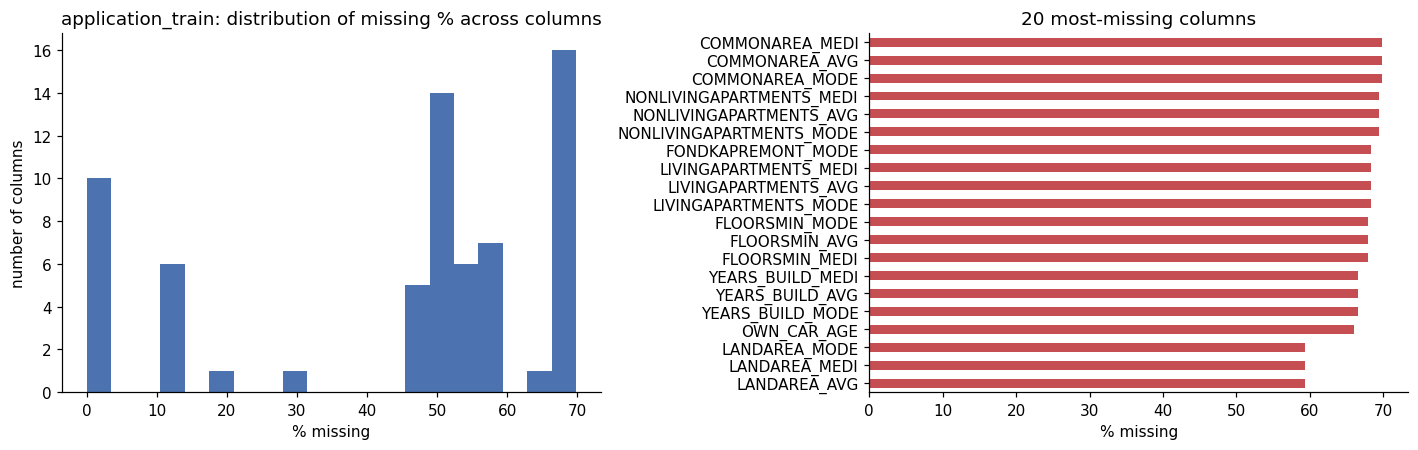

In [8]:
miss = pd.DataFrame(reports["application_train"]["missing"]).T["pct"].sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(miss, bins=20, color="#4C72B0")
ax[0].set(title="application_train: distribution of missing % across columns",
          xlabel="% missing", ylabel="number of columns")
miss.tail(20).plot.barh(ax=ax[1], color="#C44E52")
ax[1].set(title="20 most-missing columns", xlabel="% missing")
plt.tight_layout(); fig.savefig(FIG / "02_missingness_application_train.png", bbox_inches="tight"); plt.show()

In [9]:
def cat_table(name):
    rows = []
    for c, v in reports[name]["categorical_cardinality"].items():
        top = dict(v["top"])
        rows.append({"column": c, "n_unique": v["n_unique"],
                     "XNA_count": top.get("XNA", 0), "XAP_count": top.get("XAP", 0),
                     "top_values": ", ".join(f"{k} ({n:,})" for k, n in v["top"][:3])})
    return pd.DataFrame(rows).sort_values("n_unique", ascending=False)

for name in ["application_train", "previous_application", "bureau", "bureau_balance",
             "POS_CASH_balance", "credit_card_balance"]:
    print(f"\n=== {name}: text columns")
    display(cat_table(name))


=== application_train: text columns


,column,n_unique,XNA_count,XAP_count,top_values
11,ORGANIZATION_TYPE,58,55374,0,"Business Entity Type 3 (67,992), XNA (55,374), Self-employed (38,412)"
9,OCCUPATION_TYPE,18,0,0,"Laborers (55,186), Sales staff (32,102), Core staff (27,570)"
5,NAME_INCOME_TYPE,8,0,0,"Working (158,774), Commercial associate (71,617), Pensioner (55,362)"
4,NAME_TYPE_SUITE,7,0,0,"Unaccompanied (248,526), Family (40,149), Spouse, partner (11,370)"
14,WALLSMATERIAL_MODE,7,0,0,"Panel (66,040), Stone, brick (64,815), Block (9,253)"
10,WEEKDAY_APPR_PROCESS_START,7,0,0,"TUESDAY (53,901), WEDNESDAY (51,934), MONDAY (50,714)"
7,NAME_FAMILY_STATUS,6,0,0,"Married (196,432), Single / not married (45,444), Civil marriage (29,775)"
8,NAME_HOUSING_TYPE,6,0,0,"House / apartment (272,868), With parents (14,840), Municipal apartment (11,183)"
6,NAME_EDUCATION_TYPE,5,0,0,"Secondary / secondary special (218,391), Higher education (74,863), Incomplete higher (10,277)"
12,FONDKAPREMONT_MODE,4,0,0,"reg oper account (73,830), reg oper spec account (12,080), not specified (5,687)"



=== previous_application: text columns


,column,n_unique,XNA_count,XAP_count,top_values
9,NAME_GOODS_CATEGORY,28,950809,0,"XNA (950,809), Mobile (224,708), Consumer Electronics (121,576)"
3,NAME_CASH_LOAN_PURPOSE,25,677918,922661,"XAP (922,661), XNA (677,918), Repairs (23,765)"
15,PRODUCT_COMBINATION,17,0,0,"Cash (285,990), POS household with interest (263,622), POS mobile with interest (220,670)"
13,NAME_SELLER_INDUSTRY,11,855720,0,"XNA (855,720), Consumer electronics (398,265), Connectivity (276,029)"
6,CODE_REJECT_REASON,9,0,1353093,"XAP (1,353,093), HC (175,231), LIMIT (55,680)"
12,CHANNEL_TYPE,8,0,0,"Credit and cash offices (719,968), Country-wide (494,690), Stone (212,083)"
7,NAME_TYPE_SUITE,7,0,0,"Unaccompanied (508,970), Family (213,263), Spouse, partner (67,069)"
1,WEEKDAY_APPR_PROCESS_START,7,0,0,"TUESDAY (255,118), WEDNESDAY (255,010), MONDAY (253,557)"
10,NAME_PORTFOLIO,5,372230,0,"POS (691,011), Cash (461,563), XNA (372,230)"
14,NAME_YIELD_GROUP,5,517215,0,"XNA (517,215), middle (385,532), high (353,331)"



=== bureau: text columns


...

,column,n_unique,XNA_count,XAP_count,top_values
0,STATUS,8,0,0,"C (13,646,993), 0 (7,499,507), X (5,810,482)"



=== POS_CASH_balance: text columns


,column,n_unique,XNA_count,XAP_count,top_values
0,NAME_CONTRACT_STATUS,9,0,0,"Active (9,151,119), Completed (744,883), Signed (87,260)"



=== credit_card_balance: text columns


,column,n_unique,XNA_count,XAP_count,top_values
0,NAME_CONTRACT_STATUS,7,0,0,"Active (3,698,436), Completed (128,918), Signed (11,058)"


In [10]:
def range_table(name, skip_suffixes=("_AVG", "_MODE", "_MEDI"), skip_prefixes=("FLAG_",)):
    r = pd.DataFrame(reports[name]["numeric_range"]).T
    keep = [c for c in r.index if not c.endswith(skip_suffixes) and not c.startswith(skip_prefixes)]
    return r.loc[keep]

for name in TABLES:
    print(f"\n=== {name}: numeric ranges | 365243 placeholder counts: {reports[name]['days_sentinel_365243']}")
    display(range_table(name).style.format("{:,.2f}"))


=== application_train: numeric ranges | 365243 placeholder counts: {'DAYS_EMPLOYED': 55374}


,min,max,n_negative
TARGET,0.00,1.00,0.00
CNT_CHILDREN,0.00,19.00,0.00
AMT_INCOME_TOTAL,"25,650.00","117,000,000.00",0.00
AMT_CREDIT,"45,000.00","4,050,000.00",0.00
AMT_ANNUITY,"1,615.50","258,025.50",0.00
AMT_GOODS_PRICE,"40,500.00","4,050,000.00",0.00
REGION_POPULATION_RELATIVE,0.00,0.07,0.00
DAYS_BIRTH,"-25,229.00","-7,489.00","307,511.00"
DAYS_EMPLOYED,"-17,912.00","365,243.00","252,135.00"
DAYS_REGISTRATION,"-24,672.00",0.00,"307,431.00"



=== application_test: numeric ranges | 365243 placeholder counts: {'DAYS_EMPLOYED': 9274}


,min,max,n_negative
CNT_CHILDREN,0.00,20.00,0.00
AMT_INCOME_TOTAL,"26,941.50","4,410,000.00",0.00
AMT_CREDIT,"45,000.00","2,245,500.00",0.00
AMT_ANNUITY,"2,295.00","180,576.00",0.00
AMT_GOODS_PRICE,"45,000.00","2,245,500.00",0.00
REGION_POPULATION_RELATIVE,0.00,0.07,0.00
DAYS_BIRTH,"-25,195.00","-7,338.00","48,744.00"
DAYS_EMPLOYED,"-17,463.00","365,243.00","39,470.00"
DAYS_REGISTRATION,"-23,722.00",0.00,"48,731.00"
DAYS_ID_PUBLISH,"-6,348.00",0.00,"48,739.00"



=== bureau: numeric ranges | 365243 placeholder counts: {}


...

,min,max,n_negative
MONTHS_BALANCE,-96.00,-1.00,"10,001,358.00"
CNT_INSTALMENT,1.00,92.00,0.00
CNT_INSTALMENT_FUTURE,0.00,85.00,0.00
SK_DPD,0.00,"4,231.00",0.00
SK_DPD_DEF,0.00,"3,595.00",0.00



=== credit_card_balance: numeric ranges | 365243 placeholder counts: {}


,min,max,n_negative
MONTHS_BALANCE,-96.00,-1.00,"3,840,312.00"
AMT_BALANCE,"-420,250.18","1,505,902.19","2,345.00"
AMT_CREDIT_LIMIT_ACTUAL,0.00,"1,350,000.00",0.00
AMT_DRAWINGS_ATM_CURRENT,"-6,827.31","2,115,000.00",1.00
AMT_DRAWINGS_CURRENT,"-6,211.62","2,287,098.31",3.00
AMT_DRAWINGS_OTHER_CURRENT,0.00,"1,529,847.00",0.00
AMT_DRAWINGS_POS_CURRENT,0.00,"2,239,274.16",0.00
AMT_INST_MIN_REGULARITY,0.00,"202,882.01",0.00
AMT_PAYMENT_CURRENT,0.00,"4,289,207.45",0.00
AMT_PAYMENT_TOTAL_CURRENT,0.00,"4,278,315.69",0.00



=== installments_payments: numeric ranges | 365243 placeholder counts: {}


,min,max,n_negative
NUM_INSTALMENT_VERSION,0.00,178.00,0.00
NUM_INSTALMENT_NUMBER,1.00,277.00,0.00
DAYS_INSTALMENT,"-2,922.00",-1.00,"13,605,401.00"
DAYS_ENTRY_PAYMENT,"-4,921.00",-1.00,"13,602,496.00"
AMT_INSTALMENT,0.00,"3,771,487.85",0.00
AMT_PAYMENT,0.00,"3,771,487.85",0.00


**Interpretation.** The ranges point to specific values that need follow-up in Section 6:
* a 365243-day placeholder in `DAYS_EMPLOYED` and in five `previous_application` date columns;
* an extreme `AMT_INCOME_TOTAL` maximum far above the bulk of the distribution;
* `bureau` end dates roughly 115 years before the application, and some negative debt;
* negative balances and receivables in `credit_card_balance`;
* `installments_payments` payment dates earlier than the earliest due date.

All `MONTHS_BALANCE`, `DAYS_DECISION`, `DAYS_INSTALMENT` and `DAYS_ENTRY_PAYMENT` values are at or before the application,
which is a first indication of no look-ahead leakage (checked formally in Section 6).

## 4. Step 2 — Keys, relationships and coverage

For each foreign key, the checks are:
* what share of child keys exist in the parent table (orphans);
* what share of parents have any child rows (coverage);
* separately, coverage for train and scoring-set (`application_test`) applicants.

In [11]:
app_train_ids = collect_ids["application_train"]["SK_ID_CURR"]
app_test_ids = collect_ids["application_test"]["SK_ID_CURR"]
parents = {"application": app_train_ids | app_test_ids,
           "bureau": collect_ids["bureau"]["SK_ID_BUREAU"],
           "previous_application": collect_ids["previous_application"]["SK_ID_PREV"]}
print("SK_ID_CURR overlap between train and test:", len(app_train_ids & app_test_ids))

ri = []
for name, cfg in TABLES.items():
    for fk, parent in cfg["fk"].items():
        child, par = collect_ids[name][fk], parents[parent]
        cpp = reports[name]["children_per_parent"][fk]
        row = {"child": name, "fk": fk, "parent": parent, "child_keys": len(child),
               "orphan_keys_pct": round(100 * len(child - par) / len(child), 2),
               "parents_with_children_pct": round(100 * len(par & child) / len(par), 2),
               "rows_per_parent_median": cpp["50%"], "rows_per_parent_max": cpp["max"]}
        if parent == "application":
            row["train_coverage_pct"] = round(100 * len(app_train_ids & child) / len(app_train_ids), 2)
            row["test_coverage_pct"] = round(100 * len(app_test_ids & child) / len(app_test_ids), 2)
        ri.append(row)
ri = pd.DataFrame(ri)
ri.to_csv(SCHEMA / "referential_integrity.csv", index=False)
print("SK_ID_PREV mapped to >1 SK_ID_CURR:",
      {t: reports[t].get("SK_ID_PREV_mapped_to_multiple_SK_ID_CURR") for t in TABLES
       if "SK_ID_PREV_mapped_to_multiple_SK_ID_CURR" in reports[t]})
ri

SK_ID_CURR overlap between train and test: 0


SK_ID_PREV mapped to >1 SK_ID_CURR: {'POS_CASH_balance': 0, 'credit_card_balance': 0, 'installments_payments': 0}


,child,fk,parent,child_keys,orphan_keys_pct,parents_with_children_pct,rows_per_parent_median,rows_per_parent_max,train_coverage_pct,test_coverage_pct
0,bureau,SK_ID_CURR,application,305811,0.00,85.84,4.0,116.0,85.69,86.82
1,bureau_balance,SK_ID_BUREAU,bureau,817395,5.27,45.11,26.0,97.0,NaN,NaN
2,previous_application,SK_ID_CURR,application,338857,0.00,95.12,4.0,77.0,94.65,98.06
3,POS_CASH_balance,SK_ID_CURR,application,337252,0.00,94.67,22.0,295.0,94.12,98.08
4,POS_CASH_balance,SK_ID_PREV,previous_application,936325,4.00,53.82,10.0,96.0,NaN,NaN
5,credit_card_balance,SK_ID_CURR,application,103558,0.00,29.07,22.0,192.0,28.26,34.16
6,credit_card_balance,SK_ID_PREV,previous_application,104307,10.90,5.56,21.0,96.0,NaN,NaN
7,installments_payments,SK_ID_CURR,application,339587,0.00,95.32,25.0,372.0,94.84,98.36
8,installments_payments,SK_ID_PREV,previous_application,997752,3.89,57.41,10.0,293.0,NaN,NaN


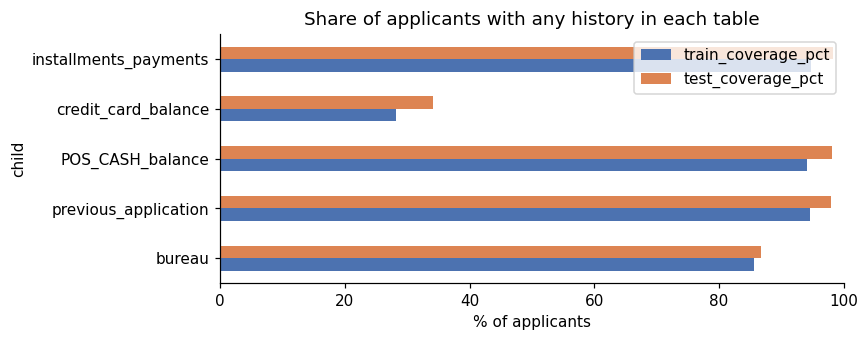

In [12]:
cov = ri[ri.parent == "application"].set_index("child")[["train_coverage_pct", "test_coverage_pct"]]
ax = cov.plot.barh(figsize=(8, 3.2), color=["#4C72B0", "#DD8452"])
ax.set(title="Share of applicants with any history in each table", xlabel="% of applicants", xlim=(0, 100))
plt.tight_layout(); plt.savefig(FIG / "02_history_coverage.png", bbox_inches="tight"); plt.show()

del collect_ids, parents
_ = gc.collect()

**Interpretation.**
* Every history table is strictly **one-to-many** from its parent, and no `SK_ID_PREV` belongs to more than one current loan.
* Joining two history tables raw on `SK_ID_CURR` would multiply rows. For example, a median applicant with 4 bureau
  credits and 4 previous applications would become 16 rows. **Every table will be aggregated to one row per `SK_ID_CURR`
  before joining.**
* Orphan keys exist (`bureau_balance` → `bureau`, and the `SK_ID_PREV` links of the three behavioural tables). Rolling up through
  the parent table would silently drop them. Tables that carry `SK_ID_CURR` will be aggregated on it directly. Bureau-balance
  orphans cannot be linked to an applicant and are documented as unusable.
* Coverage is incomplete, so **"has history" flags** will be created. A missing record is information, not a zero.

## 5. Step 2 — Target definition and class balance

,count,pct
TARGET,,
0,282686,91.927
1,24825,8.073


Negatives per positive: 11.39
Accuracy of 'always predict 0': 91.927% with recall for TARGET=1 of 0%


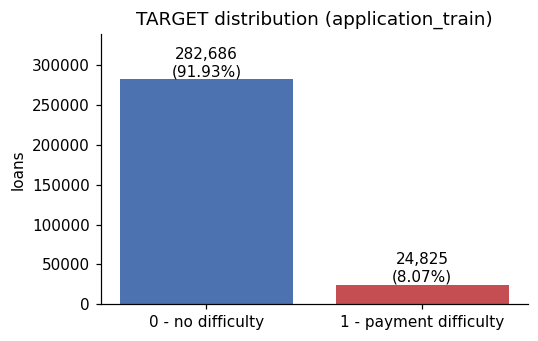

In [13]:
y = pd.read_csv(resolve("application_train.csv"), usecols=["TARGET"])["TARGET"]
tgt = pd.DataFrame({"count": y.value_counts().sort_index(), "pct": (100 * y.value_counts(normalize=True).sort_index()).round(3)})
(SCHEMA / "target_summary.json").write_text(tgt.to_json())
display(tgt)
print(f"Negatives per positive: {tgt.loc[0, 'count'] / tgt.loc[1, 'count']:.2f}")
print(f"Accuracy of 'always predict 0': {tgt.loc[0, 'pct']:.3f}% with recall for TARGET=1 of 0%")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(["0 - no difficulty", "1 - payment difficulty"], tgt["count"], color=["#4C72B0", "#C44E52"])
for i, (c, p) in enumerate(zip(tgt["count"], tgt["pct"])):
    ax.text(i, c, f"{c:,}\n({p:.2f}%)", ha="center", va="bottom")
ax.set(title="TARGET distribution (application_train)", ylabel="loans", ylim=(0, tgt["count"].max() * 1.2))
plt.tight_layout(); fig.savefig(FIG / "02_target_distribution.png", bbox_inches="tight"); plt.show()

**Interpretation.** Positives are a small minority (about 1 in 12 loans). A trivial classifier reaches high accuracy
while catching no risky applicants, which confirms the choice of ROC-AUC, PR-AUC and cost-based threshold analysis over
accuracy.

## 6. Step 2 — Targeted data-quality investigations
Each check below follows up an anomaly flagged by the inspection. Large tables load only the columns each check needs, so the notebook runs within about 4 GB of RAM. Each one records the evidence and the decision it drives.

### 6.1 Application tables

In [14]:
tr = pd.read_csv(resolve("application_train.csv"))
te = pd.read_csv(resolve("application_test.csv"))

s = tr.DAYS_EMPLOYED == SENTINEL_DAYS
print(f"DAYS_EMPLOYED == 365243: {s.sum():,} rows ({100 * s.mean():.2f}% of train)")
display(pd.crosstab(tr.NAME_INCOME_TYPE, s.rename("is_365243")))
print("Sentinel rows with ORGANIZATION_TYPE == 'XNA':", (tr.loc[s, "ORGANIZATION_TYPE"] == "XNA").sum(), "of", s.sum())
print(f"TARGET rate: sentinel {100 * tr.TARGET[s].mean():.2f}% vs others {100 * tr.TARGET[~s].mean():.2f}%")

DAYS_EMPLOYED == 365243: 55,374 rows (18.01% of train)


is_365243,False,True
NAME_INCOME_TYPE,,
Businessman,10,0
Commercial associate,71617,0
Maternity leave,5,0
Pensioner,10,55352
State servant,21703,0
Student,18,0
Unemployed,0,22
Working,158774,0


Sentinel rows with ORGANIZATION_TYPE == 'XNA': 55374 of 55374
TARGET rate: sentinel 5.40% vs others 8.66%


**Decision.** `365243` is a coded value for applicants without employment (pensioners and the unemployed), not a
measurement error. These applicants have a lower payment-difficulty rate. Deleting them would discard a large, comparatively
low-risk segment. The value will be set to missing and a `NOT_EMPLOYED` flag added.

In [15]:
inc = tr.AMT_INCOME_TOTAL
print("Income quantiles:", inc.quantile([.01, .5, .99, .999]).to_dict())
print(f"Rows > 1M: {(inc > 1e6).sum()} | rows > 10M: {(inc > 1e7).sum()}")
display(tr.nlargest(3, "AMT_INCOME_TOTAL")[["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "NAME_INCOME_TYPE", "TARGET"]])
print("CODE_GENDER == 'XNA': train", (tr.CODE_GENDER == "XNA").sum(), "| test", (te.CODE_GENDER == "XNA").sum())
print("Rare categories present in only one of train/test:")
for c in tr.select_dtypes(exclude="number").columns:
    a, b = set(tr[c].dropna()), set(te[c].dropna())
    if a ^ b:
        print(f"  {c}: train-only {sorted(a - b)} | test-only {sorted(b - a)}")

Income quantiles: {0.01: 45000.0, 0.5: 147150.0, 0.99: 472500.0, 0.999: 900000.0}
Rows > 1M: 250 | rows > 10M: 3


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NAME_INCOME_TYPE,TARGET
12840,117000000.0,562491.0,26194.5,Working,1
203693,18000090.0,675000.0,69295.5,Commercial associate,0
246858,13500000.0,1400503.5,130945.5,Commercial associate,0


CODE_GENDER == 'XNA': train 4 | test 0
Rare categories present in only one of train/test:


  CODE_GENDER: train-only ['XNA'] | test-only []


  NAME_INCOME_TYPE: train-only ['Maternity leave'] | test-only []


  NAME_FAMILY_STATUS: train-only ['Unknown'] | test-only []


**Decision.** The maximum income is orders of magnitude above the 99.9th percentile, yet the loan attached to it is ordinary.
That pattern points to a data-entry error rather than a genuine high earner. No rows are deleted. Instead:
* log transforms, plus percentile capping fitted inside training folds only;
* ratio features (credit/income, annuity/income), which are robust to such values.

Categories that exist only in train (`CODE_GENDER = 'XNA'`, some income and family-status levels) are merged into missing or
"rare", so the model cannot learn a level it will never see in production.

In [16]:
rows = []
for c in tr.columns.drop(["SK_ID_CURR", "TARGET"]):
    m = tr[c].isna()
    if m.any():
        rows.append({"column": c, "train_miss_pct": 100 * m.mean(), "test_miss_pct": 100 * te[c].isna().mean(),
                     "target_pct_if_missing": 100 * tr.TARGET[m].mean(),
                     "target_pct_if_present": 100 * tr.TARGET[~m].mean()})
mt = pd.DataFrame(rows).set_index("column").round(2)
mt["lift_missing_vs_present"] = (mt.target_pct_if_missing / mt.target_pct_if_present).round(2)
mt.to_csv(SCHEMA / "missingness_vs_target.csv")
focus = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "OWN_CAR_AGE", "COMMONAREA_AVG",
         "OCCUPATION_TYPE", "AMT_REQ_CREDIT_BUREAU_YEAR"]
display(mt.loc[focus])

building = [c for c in tr.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
attr_counts = Counter(c.rsplit("_", 1)[0] for c in building)
print(f"Building-information columns: {len(building)} = {sum(v == 3 for v in attr_counts.values())} attributes "
      f"x AVG/MODE/MEDI + {sum(v == 1 for v in attr_counts.values())} mode-only attributes")
print(f"Rows with all building columns missing: {100 * tr[building].isna().all(axis=1).mean():.2f}%")

,train_miss_pct,test_miss_pct,target_pct_if_missing,target_pct_if_present,lift_missing_vs_present
column,,,,,
EXT_SOURCE_1,56.38,42.12,8.52,7.50,1.14
EXT_SOURCE_2,0.21,0.02,7.88,8.07,0.98
EXT_SOURCE_3,19.83,17.78,9.31,7.77,1.20
OWN_CAR_AGE,65.99,66.29,8.50,7.24,1.17
COMMONAREA_AVG,69.87,68.72,8.57,6.91,1.24
OCCUPATION_TYPE,31.35,32.01,6.51,8.79,0.74
AMT_REQ_CREDIT_BUREAU_YEAR,13.50,12.41,10.34,7.72,1.34


Building-information columns: 47 = 14 attributes x AVG/MODE/MEDI + 5 mode-only attributes
Rows with all building columns missing: 47.40%


**Decision.** Missingness is **not random** and carries risk signal in both directions. For example, missing
`OCCUPATION_TYPE` coincides with lower risk because it largely overlaps with pensioners. That is an association, not a causal
effect. Consequences:
* no column is dropped for missingness alone;
* the tree model uses native missing-value handling;
* Logistic Regression gets median imputation plus missing-indicator columns;
* the redundant AVG/MODE/MEDI building triplets are reviewed for redundancy in Step 4.

In [17]:
print("Absolute calendar-date columns in application table:",
      [c for c in tr.columns if "DATE" in c.upper() and not c.startswith("DAYS")] or "none")

Absolute calendar-date columns in application table: none


### 6.2 Bureau

In [18]:
b = pd.read_csv(resolve("bureau.csv"))
pct = lambda x: f"{x:,} ({100 * x / len(b):.2f}%)"
checks = {
    "DAYS_CREDIT_UPDATE > 0 (record updated AFTER application)": (b.DAYS_CREDIT_UPDATE > 0).sum(),
    "DAYS_CREDIT_ENDDATE < -2922 (before earliest DAYS_CREDIT)": (b.DAYS_CREDIT_ENDDATE < -2922).sum(),
    "DAYS_ENDDATE_FACT < DAYS_CREDIT (closed before opened)": (b.DAYS_ENDDATE_FACT < b.DAYS_CREDIT).sum(),
    "AMT_CREDIT_SUM_DEBT < 0": (b.AMT_CREDIT_SUM_DEBT < 0).sum(),
    "AMT_CREDIT_SUM == 0": (b.AMT_CREDIT_SUM == 0).sum(),
    "CREDIT_DAY_OVERDUE > 0": (b.CREDIT_DAY_OVERDUE > 0).sum(),
    "CREDIT_DAY_OVERDUE > 90": (b.CREDIT_DAY_OVERDUE > 90).sum(),
    "CREDIT_ACTIVE == 'Active' but DAYS_ENDDATE_FACT filled": ((b.CREDIT_ACTIVE == "Active") & b.DAYS_ENDDATE_FACT.notna()).sum(),
}
display(pd.Series({k: pct(v) for k, v in checks.items()}, name="rows").to_frame())
print("DAYS_CREDIT range:", b.DAYS_CREDIT.min(), "to", b.DAYS_CREDIT.max())
del b
_ = gc.collect()

,rows
DAYS_CREDIT_UPDATE > 0 (record updated AFTER application),17 (0.00%)
DAYS_CREDIT_ENDDATE < -2922 (before earliest DAYS_CREDIT),150 (0.01%)
DAYS_ENDDATE_FACT < DAYS_CREDIT (closed before opened),20 (0.00%)
AMT_CREDIT_SUM_DEBT < 0,"8,418 (0.49%)"
AMT_CREDIT_SUM == 0,"66,582 (3.88%)"
CREDIT_DAY_OVERDUE > 0,"4,217 (0.25%)"
CREDIT_DAY_OVERDUE > 90,"1,274 (0.07%)"
CREDIT_ACTIVE == 'Active' but DAYS_ENDDATE_FACT filled,"1,969 (0.11%)"


DAYS_CREDIT range: -2922 to 0


**Decision.**
* Impossible dates are set to missing.
* Negative debt is kept (it plausibly reflects overpayment), with a flag.
* Records with `DAYS_CREDIT_UPDATE > 0` contain information from after the decision date and are excluded from
  update-based features. The count is tiny, but the rule matters for deployment.

### 6.3 Previous applications

In [19]:
p = pd.read_csv(resolve("previous_application.csv"),
                usecols=lambda c: c.startswith("DAYS_") or c in {"NAME_CONTRACT_STATUS", "AMT_CREDIT",
                        "FLAG_LAST_APPL_PER_CONTRACT", "NFLAG_LAST_APPL_IN_DAY", "SELLERPLACE_AREA"})
display(pd.crosstab(p.NAME_CONTRACT_STATUS, (p.AMT_CREDIT == 0).rename("AMT_CREDIT == 0"), margins=True))
print("FLAG_LAST_APPL_PER_CONTRACT == 'N':", (p.FLAG_LAST_APPL_PER_CONTRACT == "N").sum())
print("NFLAG_LAST_APPL_IN_DAY == 0:", (p.NFLAG_LAST_APPL_IN_DAY == 0).sum())
print("DAYS_DECISION range:", p.DAYS_DECISION.min(), "to", p.DAYS_DECISION.max())
print("365243 placeholder counts:", {c: int((p[c] == SENTINEL_DAYS).sum()) for c in p.columns if c.startswith("DAYS_")
                                     and (p[c] == SENTINEL_DAYS).any()})
print("SELLERPLACE_AREA == -1:", (p.SELLERPLACE_AREA == -1).sum())
del p
_ = gc.collect()

AMT_CREDIT == 0,False,True,All
NAME_CONTRACT_STATUS,,,
Approved,1035230,1551,1036781
Canceled,10753,305566,316319
Refused,261519,29159,290678
Unused offer,25944,492,26436
All,1333446,336768,1670214


FLAG_LAST_APPL_PER_CONTRACT == 'N': 8475
NFLAG_LAST_APPL_IN_DAY == 0: 5900
DAYS_DECISION range: -2922 to -1
365243 placeholder counts: {'DAYS_FIRST_DRAWING': 934444, 'DAYS_FIRST_DUE': 40645, 'DAYS_LAST_DUE_1ST_VERSION': 93864, 'DAYS_LAST_DUE': 211221, 'DAYS_TERMINATION': 225913}
SELLERPLACE_AREA == -1: 762675


**Decision.**
* Cancelled and many refused applications carry `AMT_CREDIT = 0`, meaning no credit was issued, not a zero-value loan.
  Amount statistics will therefore be computed on approved contracts only, while counts and refusal rates use all applications.
* Non-final application versions are filtered out.
* The `365243` placeholder is converted to missing.
* `DAYS_DECISION` is always before the current application, so there is no look-ahead.

### 6.4 Repeat clients

In [20]:
fp = ["DAYS_BIRTH", "CODE_GENDER", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH"]
print("Train rows sharing a fingerprint:", tr.duplicated(fp, keep=False).sum())
print("Train rows whose fingerprint also occurs in test:", len(tr[fp].merge(te[fp].drop_duplicates(), on=fp)))

Train rows sharing a fingerprint: 1176
Train rows whose fingerprint also occurs in test: 1


**Interpretation.** Because `SK_ID_CURR` identifies a loan, one person could hold several rows. The fingerprint check is
**unreliable in both directions**. Its fields are measured relative to each application's own date, so the same person applying
on two different dates would not match, while different people could match by coincidence. Repeat clients therefore cannot be
grouped during validation. This is documented as a residual risk of mildly optimistic validation scores.

### 6.5 Installment payments

In [21]:
# Memory-lean approach: one int64 instalment key + NumPy reduceat instead of a 3-column groupby
inst = pd.read_csv(resolve("installments_payments.csv"),
                   usecols=["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER", "DAYS_INSTALMENT",
                            "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"],
                   dtype={"SK_ID_PREV": "int32", "NUM_INSTALMENT_VERSION": "float32", "NUM_INSTALMENT_NUMBER": "int16",
                          "DAYS_INSTALMENT": "float32", "DAYS_ENTRY_PAYMENT": "float32",
                          "AMT_INSTALMENT": "float64", "AMT_PAYMENT": "float64"})
n = len(inst)
print(f"Rows: {n:,}")
print("NUM_INSTALMENT_VERSION always integer:", bool((inst.NUM_INSTALMENT_VERSION % 1 == 0).all()))
print(f"Credit-card instalments (version 0): {(inst.NUM_INSTALMENT_VERSION == 0).sum():,} rows")
print(f"Rows with payment AFTER application (DAYS_ENTRY_PAYMENT > 0): {(inst.DAYS_ENTRY_PAYMENT > 0).sum()}")
print(f"Rows with due date AFTER application (DAYS_INSTALMENT > 0): {(inst.DAYS_INSTALMENT > 0).sum()}")
both = inst.AMT_PAYMENT.isna() & inst.DAYS_ENTRY_PAYMENT.isna()
print(f"Rows missing payment amount AND date: {both.sum():,} "
      f"(amount missing {inst.AMT_PAYMENT.isna().sum():,}, date missing {inst.DAYS_ENTRY_PAYMENT.isna().sum():,})")
late_rows = inst.DAYS_ENTRY_PAYMENT > inst.DAYS_INSTALMENT
print(f"Row level - paid after due date: {late_rows.sum():,} ({100 * late_rows.mean():.2f}% of rows)")
early = inst.DAYS_INSTALMENT - inst.DAYS_ENTRY_PAYMENT
print("Days paid early (due - paid) quantiles:", early.quantile([.5, .99, .999, 1]).round(0).to_dict())
row_under = inst.AMT_PAYMENT < inst.AMT_INSTALMENT - 0.01
print(f"Row level - payment below instalment: {row_under.sum():,} ({100 * row_under.mean():.2f}% of rows)")
del both, late_rows, early, row_under

key = (inst.SK_ID_PREV.to_numpy(np.int64) * 1_000_000
       + inst.NUM_INSTALMENT_VERSION.to_numpy().astype(np.int64) * 1_000
       + inst.NUM_INSTALMENT_NUMBER.to_numpy(np.int64))
order = np.argsort(key, kind="stable")
key = key[order]
starts = np.flatnonzero(np.r_[True, key[1:] != key[:-1]])
del key
rows_per = np.diff(np.r_[starts, n])
take = lambda col: inst[col].to_numpy()[order]
amt_due = take("AMT_INSTALMENT")
due_min, due_max = np.minimum.reduceat(amt_due, starts), np.maximum.reduceat(amt_due, starts)
del amt_due
paid = np.add.reduceat(np.nan_to_num(take("AMT_PAYMENT")), starts)
due_day = np.maximum.reduceat(take("DAYS_INSTALMENT"), starts)
last_pay = np.fmax.reduceat(take("DAYS_ENTRY_PAYMENT"), starts)
del inst, order; gc.collect()

vals, cnts = np.unique(rows_per, return_counts=True)
print(f"\nDistinct instalments: {len(starts):,} | instalments with >1 row: {(rows_per > 1).sum():,} "
      f"| extra rows beyond one per instalment: {n - len(starts):,}")
display(pd.DataFrame({"rows_per_instalment": vals, "instalments": cnts}).set_index("rows_per_instalment"))
print("Instalments whose AMT_INSTALMENT differs between rows:", int((due_min != due_max).sum()))

has_pay = ~np.isnan(last_pay)
under = (paid < due_max - 0.01) & has_pay
late_inst = (last_pay > due_day) & has_pay
print(f"Instalment level (payments summed first, {has_pay.sum():,} instalments with a payment): "
      f"underpaid {under.sum():,} ({100 * under.sum() / has_pay.sum():.2f}%), "
      f"last payment after due date {late_inst.sum():,} ({100 * late_inst.sum() / has_pay.sum():.2f}%)")
del rows_per, due_min, due_max, paid, due_day, last_pay, has_pay, under, late_inst
_ = gc.collect()

Rows: 13,605,401


NUM_INSTALMENT_VERSION always integer: True
Credit-card instalments (version 0): 4,082,498 rows
Rows with payment AFTER application (DAYS_ENTRY_PAYMENT > 0): 0
Rows with due date AFTER application (DAYS_INSTALMENT > 0): 0
Rows missing payment amount AND date: 2,905 (amount missing 2,905, date missing 2,905)
Row level - paid after due date: 1,146,669 (8.43% of rows)


Days paid early (due - paid) quantiles: {0.5: 6.0, 0.99: 60.0, 0.999: 135.0, 1.0: 3189.0}
Row level - payment below instalment: 1,295,493 (9.52% of rows)



Distinct instalments: 12,951,918 | instalments with >1 row: 640,905 | extra rows beyond one per instalment: 653,483


,instalments
rows_per_instalment,
1,12311013
2,629210
3,11000
4,578
5,70
6,34
7,7
8,4
9,1


Instalments whose AMT_INSTALMENT differs between rows: 0
Instalment level (payments summed first, 12,949,013 instalments with a payment): underpaid 2,934 (0.02%), last payment after due date 1,103,475 (8.52%)


**Decision.**
* The table's true grain is **one row per payment**, not per instalment. Underpayment and lateness must be computed **after
  summing payments per instalment**. A row-level comparison overstates underpayment because a split payment looks like several
  shortfalls.
* No payment or due date falls after the current application, so this table carries no look-ahead leakage.
* Rows missing both payment amount and date are treated as instalments with no recorded payment.
* A few payments occur long before their due date. These are kept, but "days early" will be capped so they cannot dominate
  averages.

## 7. Step 2 — Train vs scoring-set (`application_test`) differences
If the unlabelled scoring set were a random draw from the same population, the distributions below would be close.

In [22]:
shift = pd.DataFrame({
    "train_%": (100 * tr.NAME_CONTRACT_TYPE.value_counts(normalize=True)).round(2),
    "test_%": (100 * te.NAME_CONTRACT_TYPE.value_counts(normalize=True)).round(2)})
display(shift)

common = [c for c in te.columns if c != "SK_ID_CURR"]
md_diff = pd.DataFrame({"train_miss_%": 100 * tr[common].isna().mean(), "test_miss_%": 100 * te[common].isna().mean()})
md_diff["abs_diff_pp"] = (md_diff["train_miss_%"] - md_diff["test_miss_%"]).abs()
display(md_diff.sort_values("abs_diff_pp", ascending=False).head(8).round(2))

num = ["AMT_CREDIT", "AMT_INCOME_TOTAL", "AMT_ANNUITY", "DAYS_BIRTH", "EXT_SOURCE_2", "EXT_SOURCE_3"]
display(pd.DataFrame({"train_median": tr[num].median(), "test_median": te[num].median()}).round(3))

,train_%,test_%
NAME_CONTRACT_TYPE,,
Cash loans,90.48,99.1
Revolving loans,9.52,0.9


,train_miss_%,test_miss_%,abs_diff_pp
EXT_SOURCE_1,56.38,42.12,14.26
EXT_SOURCE_3,19.83,17.78,2.04
ENTRANCES_AVG,50.35,48.37,1.98
ENTRANCES_MODE,50.35,48.37,1.98
ENTRANCES_MEDI,50.35,48.37,1.98
FLOORSMAX_MEDI,49.76,47.84,1.92
FLOORSMAX_MODE,49.76,47.84,1.92
FLOORSMAX_AVG,49.76,47.84,1.92


,train_median,test_median
AMT_CREDIT,513531.000,450000.000
AMT_INCOME_TOTAL,147150.000,157500.000
AMT_ANNUITY,24903.000,26199.000
DAYS_BIRTH,-15750.000,-15785.000
EXT_SOURCE_2,0.566,0.559
EXT_SOURCE_3,0.535,0.519


**Interpretation.** The test set differs materially from train: revolving loans are far rarer, and `EXT_SOURCE_1` is missing
much less often. The likely explanation is a different period or product mix, but the files do not document it. Consequences:
* holdout performance from train may not carry over to new applications;
* holdout metrics will be reported separately for cash and revolving loans;
* drift monitoring becomes a concrete recommendation in Step 11.

## 8. Step 2 — Validation design (locked)

1. **No out-of-time split.** No calendar-date column exists (Sections 2.3 and 6.1). This limitation is stated rather than
   replaced with an invented time proxy.
2. **Locked holdout.** A stratified 80/20 split of `application_train` with `SEED = 42`. The holdout is touched once, for final
   evaluation.
3. **Tuning.** Stratified 5-fold cross-validation on the 80% development set. The fold assignment is saved and reused for every model.
   Imputers, scalers, encoders and any resampling are fitted inside training folds only.
4. **Repeat clients cannot be grouped** (Section 6.4). This residual risk is documented.
5. **The unlabelled scoring set (`application_test`)** is used only to generate final predictions, never for selection, thresholds or tuning.

In [23]:
ids = tr[["SK_ID_CURR", "TARGET", "NAME_CONTRACT_TYPE"]]
dev, hold = train_test_split(ids, test_size=0.20, stratify=ids.TARGET, random_state=SEED)
split = pd.Series(-1, index=ids.index, name="fold")   # -1 = locked holdout
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, val_idx) in enumerate(skf.split(dev, dev.TARGET)):
    split.loc[dev.index[val_idx]] = k
assign = ids.assign(fold=split)
assign[["SK_ID_CURR", "fold"]].to_csv(PROCESSED / "split_assignment.csv", index=False)

check = assign.assign(partition=np.where(assign.fold == -1, "holdout", "dev fold " + assign.fold.astype(str)))
display(check.groupby("partition").agg(
    rows=("TARGET", "size"), positives=("TARGET", "sum"),
    target_pct=("TARGET", lambda s: round(100 * s.mean(), 3)),
    revolving_pct=("NAME_CONTRACT_TYPE", lambda s: round(100 * (s == "Revolving loans").mean(), 2))))
assert set(assign.SK_ID_CURR[assign.fold == -1]).isdisjoint(assign.SK_ID_CURR[assign.fold >= 0])
print("Saved:", PROCESSED / "split_assignment.csv")

,rows,positives,target_pct,revolving_pct
partition,,,,
dev fold 0,49202,3972,8.073,9.60
dev fold 1,49202,3972,8.073,9.63
dev fold 2,49202,3972,8.073,9.51
dev fold 3,49201,3972,8.073,9.61
dev fold 4,49201,3972,8.073,9.32
holdout,61503,4965,8.073,9.48


Saved: /mnt/user-data/outputs/home-credit-scorecard-model/data/processed/split_assignment.csv


**Interpretation.** The target rate and revolving-loan share are nearly identical across the holdout and all five folds, so
every model is compared on the same, representative partitions. The assignment file is the only artefact carried into later
stages. It is keyed by `SK_ID_CURR`, so engineered features can be joined to it without re-splitting.

## 9. Summary of Steps 1–2: findings and decisions

| # | Finding (measured above) | Decision carried forward |
|---|---|---|
| 1 | `TARGET` = early payment difficulty; X and Y undisclosed | Call outputs *probability of payment difficulty*; business impact is scenario-based |
| 2 | Strong class imbalance (about 1 positive per 11 negatives) | ROC-AUC, PR-AUC, calibration and cost-based thresholds instead of accuracy |
| 3 | All history tables are one-to-many; orphan keys exist | Aggregate each table to `SK_ID_CURR` before joining; add "has history" flags |
| 4 | `installments_payments` is one row per payment, not per instalment | Sum payments per instalment before computing lateness and underpayment |
| 5 | `365243` placeholder = not employed (application) and unknown dates (previous applications) | Convert to missing and add flags; never delete these rows |
| 6 | Missingness is informative and non-random | Keep columns; use native NA handling and missing indicators |
| 7 | Extreme income values and impossible bureau dates | Fold-fitted capping and log/ratio features; null impossible dates |
| 8 | A few bureau records updated after the application | Exclude from update-based features (leakage rule) |
| 9 | Scoring set (`application_test`) differs from train (product mix, missingness) | Segment-level reporting; drift monitoring recommendation |
| 10 | No calendar dates; `SK_ID_CURR` is a loan, not a person | Stratified holdout + 5-fold CV; documented validation limitations |

**Stage status.** Steps 1–2 are complete for all eight tables. Step 3 follows in Section 10.

## 10. Step 3 — Exploratory data analysis focused on underwriting questions

**Objective.** Find the patterns that should shape underwriting and modelling decisions, not produce charts for their own sake.

**Rules for this stage**
* **Development partition only.** Folds 0–4 (246,008 loans) are analysed. The 61,503-loan holdout is never inspected, so no EDA
  insight can leak into the final evaluation.
* **Uncertainty is shown.** Default rates by group carry 95% Wilson confidence intervals. Groups below 200 loans (100 for bins) are hidden.
* **Stability is checked.** Single-feature ROC-AUC is computed in each of the five folds; a small spread means the pattern is not noise.
* **Association, not causation.** Every pattern is observational, and many variables overlap (for example, pensioners are older).
* **Derived fields here are exploratory.** History indicators are aggregated to one row per applicant *before* joining, as required
  by Section 4. Formal, fold-safe feature engineering is done in Steps 4–5.

**Business questions**
1. Which products and applicant segments carry above-average risk?
2. How do age and employment stability relate to risk?
3. Do affordability ratios behave the way underwriting rules assume?
4. How much do external credit scores contribute, and what are their risks?
5. Does past behaviour (refusals, bureau debt, late instalments, card utilisation) predict payment difficulty?
6. Which variables rank risk best on their own, and is that stable?
7. Which variables are redundant?

In [24]:
# ---- Step 3 setup: development partition only (holdout is never inspected) ----
from sklearn.metrics import roc_auc_score

assign = pd.read_csv(PROCESSED / "split_assignment.csv")
dev_ids = set(assign.loc[assign.fold >= 0, "SK_ID_CURR"])
eda = tr[tr.SK_ID_CURR.isin(dev_ids)].merge(assign, on="SK_ID_CURR").reset_index(drop=True)
APP_NUMERIC = [c for c in tr.select_dtypes("number").columns if c not in {"SK_ID_CURR", "TARGET"}]
del tr, te; gc.collect()                      # free memory: the EDA works on the development rows only
BASE = eda.TARGET.mean()
print(f"EDA population: {len(eda):,} development loans | holdout excluded: {(assign.fold == -1).sum():,} | "
      f"base TARGET rate {100 * BASE:.2f}%")

# EDA-only derived fields (formal, fold-safe feature engineering happens in Steps 4-5)
emp = eda.DAYS_EMPLOYED.replace(SENTINEL_DAYS, np.nan)
eda = pd.concat([eda.drop(columns="DAYS_EMPLOYED"), pd.DataFrame({
    "DAYS_EMPLOYED": emp,
    "NOT_EMPLOYED": (eda.DAYS_EMPLOYED == SENTINEL_DAYS).astype(int),
    "AGE_YEARS": -eda.DAYS_BIRTH / 365.25,
    "EMPLOYED_YEARS": -emp / 365.25,
    "CREDIT_TO_INCOME": eda.AMT_CREDIT / eda.AMT_INCOME_TOTAL,
    "ANNUITY_TO_INCOME": eda.AMT_ANNUITY / eda.AMT_INCOME_TOTAL,
    "CREDIT_TO_GOODS": eda.AMT_CREDIT / eda.AMT_GOODS_PRICE,
    "CREDIT_TERM_MONTHS": eda.AMT_CREDIT / eda.AMT_ANNUITY})], axis=1).copy()   # .copy() consolidates blocks

EDA population: 246,008 development loans | holdout excluded: 61,503 | base TARGET rate 8.07%


In [25]:
# ---- Reusable EDA helpers ----
def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion (robust for small groups and rare events)."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def rate_table(df, col, min_n=200, order=None):
    g = df.groupby(col, observed=True, dropna=False)["TARGET"].agg(n="size", positives="sum")
    g = g[g.n >= min_n]
    g["rate_pct"] = 100 * g.positives / g.n
    lo, hi = wilson(g.positives, g.n)
    g["ci_low"], g["ci_high"] = 100 * lo, 100 * hi
    g["share_pct"] = 100 * g.n / len(df)
    g["lift"] = g.rate_pct / (100 * BASE)
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    return g.round(2)


def plot_rates(t, ax, title):
    y = np.arange(len(t))
    ax.barh(y, t.rate_pct, xerr=[t.rate_pct - t.ci_low, t.ci_high - t.rate_pct],
            color=np.where(t.rate_pct > 100 * BASE, "#C44E52", "#4C72B0"), capsize=2)
    ax.axvline(100 * BASE, ls="--", c="grey", lw=1)
    ax.set_yticks(y, [f"{i} (n={n:,})" for i, n in zip(t.index.astype(str), t.n)], fontsize=8)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="TARGET rate % (95% CI); dashed = portfolio")


def binned(df, col, q=10, labels_fmt="{:.2f}"):
    """Quantile bins plus an explicit 'Missing' bin, so missingness is analysed rather than hidden."""
    x = df[col]
    b = pd.qcut(x, q=q, duplicates="drop")
    lab = b.cat.categories
    names = [f"{labels_fmt.format(i.left)}–{labels_fmt.format(i.right)}" for i in lab]
    b = b.cat.rename_categories(names).cat.add_categories("Missing").fillna("Missing")
    return b


def univariate_auc(x, y):
    """ROC-AUC of a single feature on rows where it is present, oriented so that >= 0.5.
    Direction '+' means higher values go with higher risk."""
    m = x.notna()
    if m.sum() < 1000 or y[m].nunique() < 2:
        return np.nan, ""
    a = roc_auc_score(y[m], x[m])
    return (a, "+") if a >= 0.5 else (1 - a, "-")

### 10.1 Product and applicant segments


--- NAME_CONTRACT_TYPE


,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
NAME_CONTRACT_TYPE,,,,,,,
Cash loans,222560,18572,8.34,8.23,8.46,90.47,1.03
Revolving loans,23448,1288,5.49,5.21,5.79,9.53,0.68



--- NAME_INCOME_TYPE


,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
NAME_INCOME_TYPE,,,,,,,
Commercial associate,57273,4348,7.59,7.38,7.81,23.28,0.94
Pensioner,44134,2365,5.36,5.15,5.57,17.94,0.66
State servant,17518,1024,5.85,5.51,6.20,7.12,0.72
Working,127043,12118,9.54,9.38,9.70,51.64,1.18



--- NAME_EDUCATION_TYPE


...

,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
NAME_FAMILY_STATUS,,,,,,,
Civil marriage,23812,2385,10.02,9.64,10.40,9.68,1.24
Married,157153,11840,7.53,7.40,7.67,63.88,0.93
Separated,15840,1265,7.99,7.57,8.42,6.44,0.99
Single / not married,36359,3616,9.95,9.64,10.26,14.78,1.23
Widow,12842,754,5.87,5.48,6.29,5.22,0.73



--- NAME_HOUSING_TYPE


,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
NAME_HOUSING_TYPE,,,,,,,
Co-op apartment,882,78,8.84,7.14,10.90,0.36,1.10
House / apartment,218383,17020,7.79,7.68,7.91,88.77,0.97
Municipal apartment,8916,758,8.50,7.94,9.10,3.62,1.05
Office apartment,2097,136,6.49,5.51,7.62,0.85,0.80
Rented apartment,3873,478,12.34,11.34,13.42,1.57,1.53
With parents,11857,1390,11.72,11.16,12.31,4.82,1.45



--- CODE_GENDER


,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
CODE_GENDER,,,,,,,
F,161887,11334,7.00,6.88,7.13,65.81,0.87
M,84119,8526,10.14,9.93,10.34,34.19,1.26


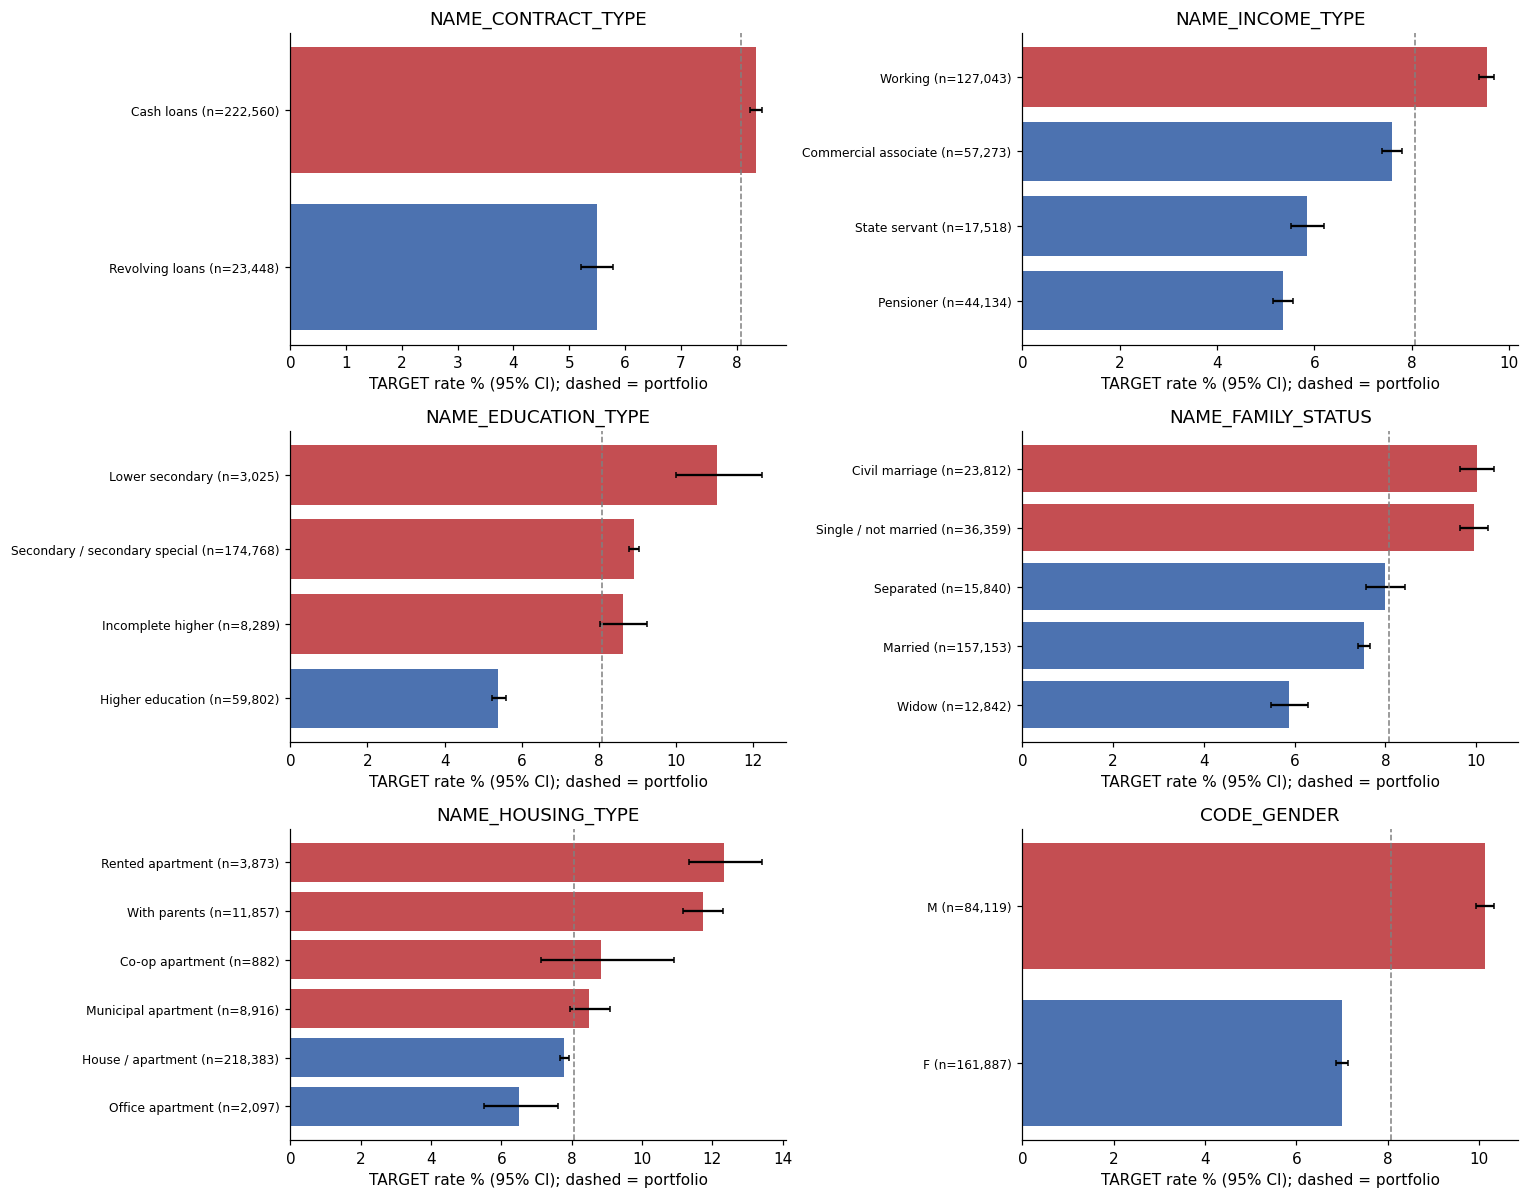

In [26]:
seg_cols = ["NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
            "NAME_HOUSING_TYPE", "CODE_GENDER"]
seg = {c: rate_table(eda, c) for c in seg_cols}
for c, t in seg.items():
    print(f"\n--- {c}")
    display(t)

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
for ax, (c, t) in zip(axes.ravel(), seg.items()):
    plot_rates(t.sort_values("rate_pct", ascending=False), ax, c)
plt.tight_layout(); fig.savefig(FIG / "03_segment_risk.png", bbox_inches="tight"); plt.show()

,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
OCCUPATION_TYPE,,,,,,,
Low-skill Laborers,1696,307,18.10,16.34,20.01,0.69,2.24
Waiters/barmen staff,1046,120,11.47,9.68,13.55,0.43,1.42
Drivers,14944,1683,11.26,10.77,11.78,6.07,1.40
Security staff,5372,574,10.69,9.89,11.54,2.18,1.32
Laborers,44259,4657,10.52,10.24,10.81,17.99,1.30
Cooking staff,4767,501,10.51,9.67,11.41,1.94,1.30
Sales staff,25606,2458,9.60,9.24,9.97,10.41,1.19
Cleaning staff,3741,357,9.54,8.64,10.53,1.52,1.18
Realty agents,594,48,8.08,6.15,10.55,0.24,1.00


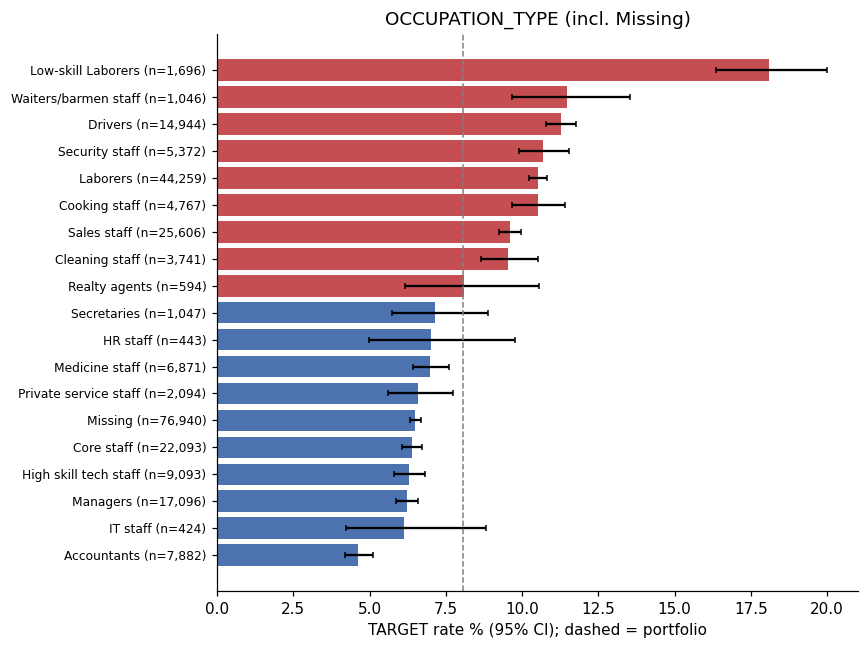

In [27]:
occ = rate_table(eda.assign(OCCUPATION_TYPE=eda.OCCUPATION_TYPE.fillna("Missing")), "OCCUPATION_TYPE")
display(occ.sort_values("rate_pct", ascending=False))
fig, ax = plt.subplots(figsize=(8, 6))
plot_rates(occ.sort_values("rate_pct", ascending=False), ax, "OCCUPATION_TYPE (incl. Missing)")
plt.tight_layout(); fig.savefig(FIG / "03_occupation_risk.png", bbox_inches="tight"); plt.show()

**Findings (development data; portfolio rate 8.07%).**
* **Product.** Cash loans run at 8.34% against 5.49% for revolving loans. Because the scoring set (`application_test`) is 99.1% cash loans
  (Section 7), a production portfolio will likely show a higher rate than the blended development figure, which is another
  reason to report performance by product.
* **Income type and education.** Working applicants are at 9.54%, versus 5.36% for pensioners and 5.85% for state servants.
  Risk falls steadily with education: 11.07% for lower secondary versus 5.39% for higher education.
* **Housing.** Applicants renting (12.34%) or living with parents (11.72%) are riskier than owners (7.79%). This plausibly
  reflects life stage and asset buffers.
* **Occupation.** Rates range from 18.10% for low-skill labourers (n = 1,696) to 4.63% for accountants. A missing occupation is
  *lower* risk (6.49%) because it overlaps with pensioners. That is not a reason to reward leaving the field blank.
* **Gender.** Men show 10.14% versus 7.00% for women. Gender is a sensitive attribute. **Decision:** exclude `CODE_GENDER` from
  model inputs by default, pending compliance review, and use it in Step 11 only to check whether errors and approval rates
  differ between groups.

**Modelling decisions.** Categorical inputs need encoding with rare levels grouped (several occupations have fewer than 1,000 loans).
Overlapping segments (income type, age, occupation) mean the multivariate model, not these one-way tables, should decide
their combined weight.

### 10.2 Age and employment stability

,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
AGE_BAND,,,,,,,
20-25,9841,1224,12.44,11.80,13.10,4.00,1.54
25-30,26440,2941,11.12,10.75,11.51,10.75,1.38
30-35,31621,3267,10.33,10.00,10.67,12.85,1.28
35-40,34237,3052,8.91,8.62,9.22,13.92,1.10
40-45,33135,2634,7.95,7.66,8.25,13.47,0.98
45-50,28147,2059,7.32,7.02,7.63,11.44,0.91
50-55,28004,1857,6.63,6.35,6.93,11.38,0.82
55-60,26485,1447,5.46,5.20,5.74,10.77,0.68
60-70,28098,1379,4.91,4.66,5.17,11.42,0.61


,n,positives,rate_pct,ci_low,ci_high,share_pct,lift
EMPLOYMENT_BAND,,,,,,,
<1y,22393,2462,10.99,10.59,11.41,9.10,1.36
1-2y,25590,2943,11.50,11.12,11.90,10.40,1.42
2-5y,61228,6120,10.00,9.76,10.24,24.89,1.24
5-10y,51877,3856,7.43,7.21,7.66,21.09,0.92
10-20y,30728,1698,5.53,5.28,5.79,12.49,0.68
20y+,10049,411,4.09,3.72,4.50,4.08,0.51
Not employed (365243),44143,2370,5.37,5.16,5.58,17.94,0.67


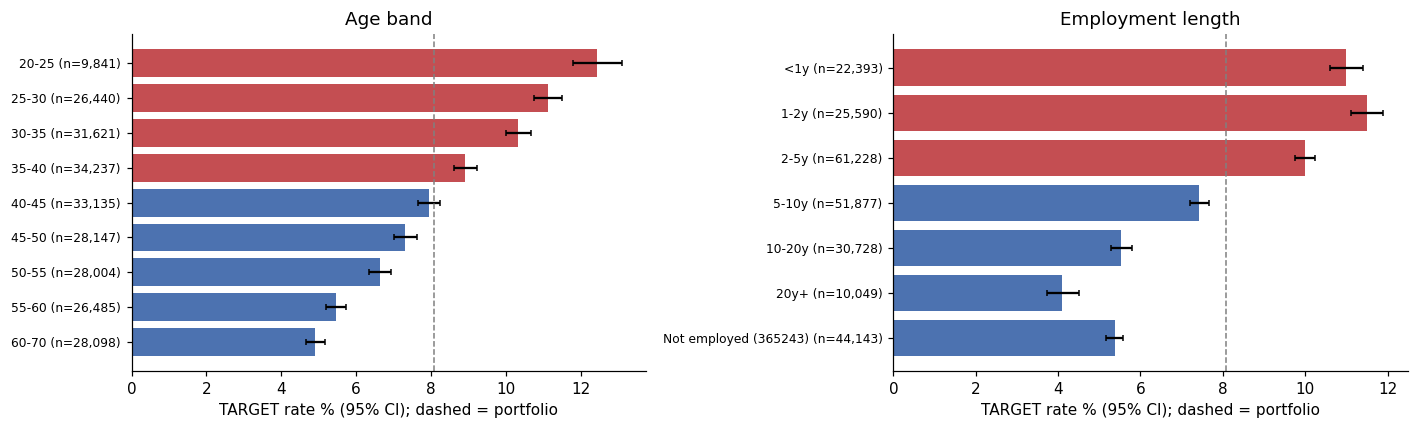

In [28]:
eda["AGE_BAND"] = pd.cut(eda.AGE_YEARS, [20, 25, 30, 35, 40, 45, 50, 55, 60, 70],
                         labels=["20-25", "25-30", "30-35", "35-40", "40-45", "45-50", "50-55", "55-60", "60-70"])
emp_band = pd.cut(eda.EMPLOYED_YEARS, [-0.01, 1, 2, 5, 10, 20, 50],
                  labels=["<1y", "1-2y", "2-5y", "5-10y", "10-20y", "20y+"]).astype(object)
eda["EMPLOYMENT_BAND"] = np.where(eda.NOT_EMPLOYED == 1, "Not employed (365243)", emp_band)
age_t = rate_table(eda, "AGE_BAND")
emp_t = rate_table(eda, "EMPLOYMENT_BAND",
                   order=["<1y", "1-2y", "2-5y", "5-10y", "10-20y", "20y+", "Not employed (365243)"])
display(age_t); display(emp_t)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_rates(age_t, ax[0], "Age band"); plot_rates(emp_t, ax[1], "Employment length")
plt.tight_layout(); fig.savefig(FIG / "03_age_employment_risk.png", bbox_inches="tight"); plt.show()

**Findings.**
* Risk falls monotonically with age, from 12.44% at 20–25 to 4.91% at 60–70 (a 2.5× spread), with tight confidence intervals.
* Employment length shows the same pattern: 11.50% at 1–2 years versus 4.09% at 20+ years. Applicants coded as not employed
  (the 365243 placeholder) sit at 5.37%, consistent with Section 6.1.

**Decisions.** Age and employment length are strong, monotone signals, so they suit Logistic Regression without complex
transformations. Some jurisdictions restrict age-based credit decisions, so age is flagged for the same compliance review as gender.

### 10.3 Affordability

,count,mean,std,min,1%,25%,50%,75%,99%,max
AMT_INCOME_TOTAL,246008.0,168853.181,258960.632,25650.000,45000.000,112500.000,147600.000,202500.000,472500.000,1.170000e+08
AMT_CREDIT,246008.0,599338.249,402725.773,45000.000,76410.000,270000.000,514777.500,808650.000,1862802.000,4.050000e+06
CREDIT_TO_INCOME,246008.0,3.959,2.688,0.005,0.596,2.019,3.269,5.169,13.036,4.922700e+01
ANNUITY_TO_INCOME,245998.0,0.181,0.095,0.000,0.039,0.115,0.163,0.229,0.484,1.571000e+00
CREDIT_TO_GOODS,245787.0,1.123,0.124,0.150,1.000,1.000,1.119,1.198,1.475,6.000000e+00
CREDIT_TERM_MONTHS,245998.0,21.624,7.821,8.037,8.734,15.647,20.000,27.100,37.795,4.530500e+01


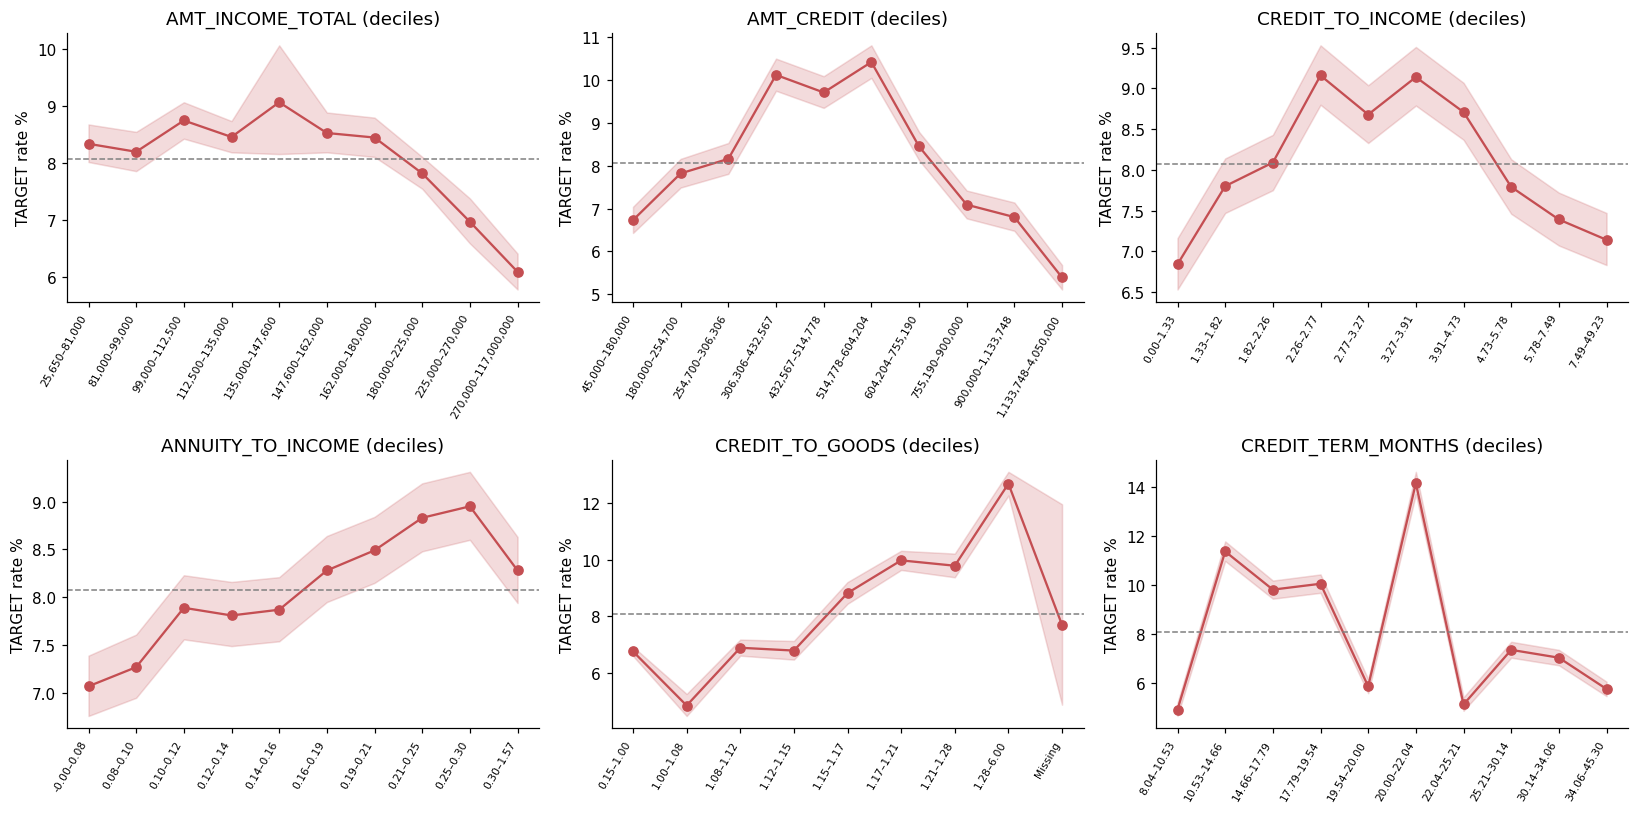


--- CREDIT_TO_INCOME by decile


,n,rate_pct,ci_low,ci_high,lift
_b,,,,,
0.00–1.33,24768,6.84,6.53,7.16,0.85
1.33–1.82,24463,7.80,7.47,8.14,0.97
1.82–2.26,24608,8.09,7.75,8.43,1.00
2.26–2.77,24589,9.16,8.80,9.53,1.13
2.77–3.27,24576,8.68,8.33,9.04,1.08
3.27–3.91,24609,9.14,8.79,9.51,1.13
3.91–4.73,24592,8.71,8.37,9.07,1.08
4.73–5.78,24601,7.79,7.46,8.13,0.97
5.78–7.49,24616,7.39,7.07,7.72,0.91



--- ANNUITY_TO_INCOME by decile


,n,rate_pct,ci_low,ci_high,lift
_b,,,,,
-0.00–0.08,25311,7.07,6.76,7.39,0.88
0.08–0.10,23889,7.27,6.95,7.61,0.90
0.10–0.12,24609,7.89,7.56,8.23,0.98
0.12–0.14,24607,7.81,7.49,8.16,0.97
0.14–0.16,24584,7.87,7.54,8.21,0.97
0.16–0.19,24624,8.28,7.95,8.64,1.03
0.19–0.21,24574,8.49,8.15,8.84,1.05
0.21–0.25,24600,8.83,8.48,9.19,1.09
0.25–0.30,24605,8.95,8.60,9.31,1.11



--- CREDIT_TO_GOODS by decile


,n,rate_pct,ci_low,ci_high,lift
_b,,,,,
0.15–1.00,86802,6.75,6.59,6.92,0.84
1.00–1.08,11632,4.83,4.46,5.24,0.60
1.08–1.12,30008,6.88,6.60,7.17,0.85
1.12–1.15,22703,6.78,6.46,7.12,0.84
1.15–1.17,20915,8.82,8.44,9.21,1.09
1.17–1.21,30345,9.98,9.64,10.32,1.24
1.21–1.28,19405,9.79,9.38,10.22,1.21
1.28–6.00,23977,12.70,12.28,13.12,1.57
Missing,221,7.69,4.86,11.97,0.95



--- CREDIT_TERM_MONTHS by decile


,n,rate_pct,ci_low,ci_high,lift
_b,,,,,
8.04–10.53,24613,4.92,4.66,5.20,0.61
10.53–14.66,24625,11.38,10.99,11.79,1.41
14.66–17.79,24564,9.82,9.45,10.19,1.22
17.79–19.54,24674,10.06,9.69,10.44,1.25
19.54–20.00,26989,5.87,5.59,6.16,0.73
20.00–22.04,22134,14.17,13.72,14.63,1.76
22.04–25.21,24661,5.13,4.87,5.42,0.64
25.21–30.14,24685,7.36,7.04,7.69,0.91
30.14–34.06,25155,7.04,6.73,7.36,0.87


In [29]:
afford = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "CREDIT_TO_INCOME", "ANNUITY_TO_INCOME",
          "CREDIT_TO_GOODS", "CREDIT_TERM_MONTHS"]
display(eda[afford].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
aff_tables = {}
for ax, c in zip(axes.ravel(), afford):
    t = rate_table(eda.assign(_b=binned(eda, c, 10, "{:,.2f}" if eda[c].median() < 100 else "{:,.0f}")), "_b", min_n=100)
    aff_tables[c] = t
    ax.plot(range(len(t)), t.rate_pct, marker="o", color="#C44E52")
    ax.fill_between(range(len(t)), t.ci_low, t.ci_high, alpha=.2, color="#C44E52")
    ax.axhline(100 * BASE, ls="--", c="grey", lw=1)
    ax.set_xticks(range(len(t)), t.index.astype(str), rotation=60, ha="right", fontsize=7)
    ax.set(title=f"{c} (deciles)", ylabel="TARGET rate %")
plt.tight_layout(); fig.savefig(FIG / "03_affordability_risk.png", bbox_inches="tight"); plt.show()
for c in ["CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "CREDIT_TO_GOODS", "CREDIT_TERM_MONTHS"]:
    print(f"\n--- {c} by decile"); display(aff_tables[c][["n", "rate_pct", "ci_low", "ci_high", "lift"]])

**Findings. Affordability does not behave the way simple underwriting rules assume.**
* **Credit-to-income is not monotonic.** Risk peaks around 9.1% in the middle deciles and is *lowest* at both extremes: 6.84% in
  the bottom decile and 7.14% in the top decile. Its single-feature AUC is 0.502, essentially no ranking power. One plausible explanation
  is selection: the lender may only grant large loans relative to income to applicants it already judged strong. The data
  cannot confirm this.
* **Annuity-to-income rises only mildly**, from 7.07% to 8.95% across the first nine deciles, with the top decile at 8.28%
  (AUC about 0.52).
* **Credit-to-goods price is the clearest affordability signal.** Loans at or below the goods price run at 6.75%
  (4.83% in the 1.00–1.08 band), while loans above 1.28× the goods price reach 12.70%. Financing well above the item's price
  (added fees, insurance or a cash component) goes with higher risk.
* **Implied term (credit ÷ annuity) has a saw-tooth pattern.** Adjacent bands range from 5.87% to 14.17%. Credit ÷ annuity mixes
  the contractual term with the interest rate: at a fixed term, a higher rate lowers the ratio. The bands therefore likely
  combine product terms with pricing tiers. If pricing came from an earlier Home Credit risk assessment, this feature partly
  re-uses that judgment. That is useful for prediction but needs recording as a model-risk dependency.

**Decisions.** No hard credit-to-income cut-off should be derived from this data. The non-linear affordability signals favour a tree
model; for Logistic Regression they will be binned (weight-of-evidence style). Note that single-feature AUC understates
non-monotonic signals: implied term has an AUC of only 0.533 despite the large differences between bands.

### 10.4 External credit scores

EXT_SOURCE_1: lowest decile 17.41% | highest decile 2.58% | missing 8.52%
EXT_SOURCE_2: lowest decile 18.28% | highest decile 2.96% | missing 7.72%
EXT_SOURCE_3: lowest decile 19.92% | highest decile 3.26% | missing 9.28%


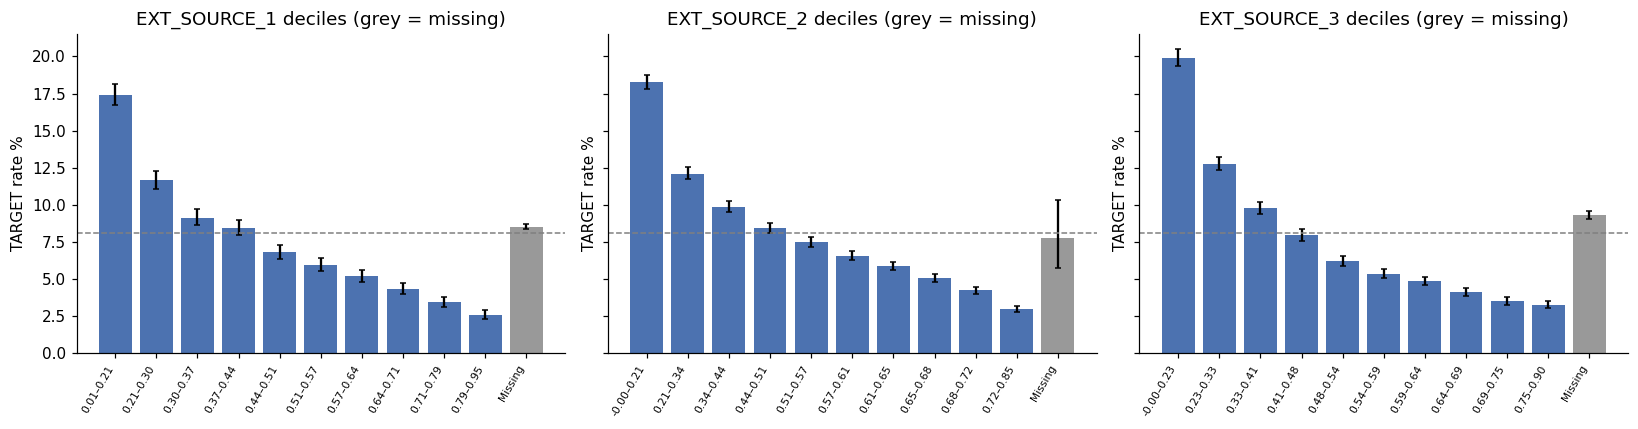


Spearman correlation among external scores (pairwise complete):


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
EXT_SOURCE_1,1.000,0.221,0.183
EXT_SOURCE_2,0.221,1.000,0.107
EXT_SOURCE_3,0.183,0.107,1.000


Correlation of each external score with AGE_YEARS: {'EXT_SOURCE_1': 0.601, 'EXT_SOURCE_2': 0.103, 'EXT_SOURCE_3': 0.207}


In [30]:
ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, c in zip(axes, ext):
    t = rate_table(eda.assign(_b=binned(eda, c, 10)), "_b", min_n=100)
    ax.bar(range(len(t)), t.rate_pct, yerr=[t.rate_pct - t.ci_low, t.ci_high - t.rate_pct],
           color=["#999999" if i == "Missing" else "#4C72B0" for i in t.index], capsize=2)
    ax.axhline(100 * BASE, ls="--", c="grey", lw=1)
    ax.set_xticks(range(len(t)), t.index.astype(str), rotation=60, ha="right", fontsize=7)
    ax.set(title=f"{c} deciles (grey = missing)", ylabel="TARGET rate %")
    print(f"{c}: lowest decile {t.rate_pct.iloc[0]:.2f}% | highest decile {t.rate_pct.iloc[-2]:.2f}% | "
          f"missing {t.loc['Missing', 'rate_pct'] if 'Missing' in t.index else float('nan'):.2f}%")
plt.tight_layout(); fig.savefig(FIG / "03_external_scores_risk.png", bbox_inches="tight"); plt.show()

print("\nSpearman correlation among external scores (pairwise complete):")
display(eda[ext].corr(method="spearman").round(3))
print("Correlation of each external score with AGE_YEARS:", eda[ext].corrwith(eda.AGE_YEARS, method="spearman").round(3).to_dict())

**Findings.**
* These are the strongest single signals in the data. For `EXT_SOURCE_1`, `_2` and `_3`, the lowest score decile has rates of
  17.41%, 18.28% and 19.92%, against 2.58%, 2.96% and 3.26% in the highest decile: roughly a 6–7× spread.
* A missing score is itself mildly risky: 8.52% for `EXT_SOURCE_1` and 9.28% for `EXT_SOURCE_3`.
* The three scores are only weakly correlated with each other (Spearman 0.11–0.22), so they are complementary rather than redundant.
* `EXT_SOURCE_1` correlates 0.60 with age, so it partly encodes age.

**Risks.** The scores' provenance is undocumented ("normalized score from external data source"). Their cost and availability
at decision time are unknown, and `EXT_SOURCE_1` coverage already differs between train and the scoring set (Section 7).

**Decisions.**
* Use the scores, but treat them as a vendor dependency to monitor.
* In Step 9, also evaluate a model **without** the external scores to quantify how much the scorecard relies on them.
* Keep missing-score indicators.

### 10.5 Repayment and credit history

Each history table is reduced to one row per `SK_ID_CURR` before joining:

| Indicator | Formula | Risk hypothesis |
|---|---|---|
| `PREV_REFUSAL_RATE` | refused ÷ all final previous Home Credit applications | Earlier refusals signal prior risk assessments |
| `BUREAU_ACTIVE_DEBT_RATIO` | Σ outstanding debt ÷ Σ credit amount, active bureau credits | High remaining debt suggests repayment pressure |
| `BUREAU_WORST_STATUS` | worst monthly DPD bucket ever across bureau credits (0–5) | Past external delinquency |
| `POS_ANY_DPD_DEF` | any POS/cash month with days past due beyond tolerance | Past internal delinquency |
| `INST_SHARE_LATE` | share of instalments whose last payment came after the due date (missed = late) | Repayment discipline |
| `INST_MAX_DAYS_LATE` | maximum days late over all instalments | Severity of past delinquency |
| `CC_AVG_UTILISATION` | mean of monthly balance ÷ limit (months with limit > 0, clipped to [−1, 3]) | Revolving credit stress |

Instalments are summed per instalment before lateness is assessed (Section 6.5).

In [31]:
# ---- Applicant-level history indicators for EDA (each table aggregated to SK_ID_CURR BEFORE joining) ----
hist = pd.DataFrame(index=pd.Index(sorted(dev_ids), name="SK_ID_CURR"))

# Previous Home Credit applications: final versions only (Section 6.3)
p = pd.read_csv(resolve("previous_application.csv"),
                usecols=["SK_ID_CURR", "NAME_CONTRACT_STATUS", "FLAG_LAST_APPL_PER_CONTRACT", "NFLAG_LAST_APPL_IN_DAY"])
p = p[(p.FLAG_LAST_APPL_PER_CONTRACT == "Y") & (p.NFLAG_LAST_APPL_IN_DAY == 1)]
pa = pd.crosstab(p.SK_ID_CURR, p.NAME_CONTRACT_STATUS)
hist["PREV_N_APPS"] = pa.sum(axis=1)
hist["PREV_N_REFUSED"] = pa.get("Refused")
hist["PREV_REFUSAL_RATE"] = hist.PREV_N_REFUSED / hist.PREV_N_APPS
del p, pa

# Credit bureau: counts, current overdue, debt load of active credits
b = pd.read_csv(resolve("bureau.csv"), usecols=["SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE", "CREDIT_DAY_OVERDUE",
                                                  "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT"])
act = b[b.CREDIT_ACTIVE == "Active"]
hist["BUREAU_N_CREDITS"] = b.groupby("SK_ID_CURR").size()
hist["BUREAU_N_ACTIVE"] = act.groupby("SK_ID_CURR").size()
hist["BUREAU_ANY_OVERDUE_NOW"] = (b.CREDIT_DAY_OVERDUE > 0).groupby(b.SK_ID_CURR).max().astype(float)
debt = act.groupby("SK_ID_CURR")[["AMT_CREDIT_SUM_DEBT", "AMT_CREDIT_SUM"]].sum()
hist["BUREAU_ACTIVE_DEBT_RATIO"] = (debt.AMT_CREDIT_SUM_DEBT / debt.AMT_CREDIT_SUM.where(debt.AMT_CREDIT_SUM > 0)).clip(-1, 5)

# Bureau monthly status: worst DPD bucket ever (0 = no DPD ... 5 = 120+ / written off), streamed in chunks
status_rank = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5}
worst = None
for ch in pd.read_csv(resolve("bureau_balance.csv"), usecols=["SK_ID_BUREAU", "STATUS"], chunksize=5_000_000):
    w = ch.STATUS.map(status_rank).groupby(ch.SK_ID_BUREAU).max()
    worst = w if worst is None else pd.concat([worst, w]).groupby(level=0).max()
bw = b[["SK_ID_CURR", "SK_ID_BUREAU"]].merge(worst.rename("w"), left_on="SK_ID_BUREAU", right_index=True)
hist["BUREAU_WORST_STATUS"] = bw.groupby("SK_ID_CURR").w.max()
del b, act, debt, worst, bw; gc.collect()

# POS / cash monthly balance: any month past due beyond tolerance
pos = pd.read_csv(resolve("POS_CASH_balance.csv"), usecols=["SK_ID_CURR", "SK_DPD_DEF"])
hist["POS_ANY_DPD_DEF"] = (pos.SK_DPD_DEF > 0).groupby(pos.SK_ID_CURR).max().astype(float)
del pos

# Credit cards: utilisation = balance / limit, averaged over months with a positive limit
cc = pd.read_csv(resolve("credit_card_balance.csv"),
                 usecols=["SK_ID_CURR", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL", "SK_DPD_DEF"])
cc = cc[cc.AMT_CREDIT_LIMIT_ACTUAL > 0]
cc["UTIL"] = (cc.AMT_BALANCE / cc.AMT_CREDIT_LIMIT_ACTUAL).clip(-1, 3)
hist["CC_AVG_UTILISATION"] = cc.groupby("SK_ID_CURR").UTIL.mean()
hist["CC_MAX_UTILISATION"] = cc.groupby("SK_ID_CURR").UTIL.max()
del cc; gc.collect()
print("Built so far:", hist.columns.tolist())

Built so far: ['PREV_N_APPS', 'PREV_N_REFUSED', 'PREV_REFUSAL_RATE', 'BUREAU_N_CREDITS', 'BUREAU_N_ACTIVE', 'BUREAU_ANY_OVERDUE_NOW', 'BUREAU_ACTIVE_DEBT_RATIO', 'BUREAU_WORST_STATUS', 'POS_ANY_DPD_DEF', 'CC_AVG_UTILISATION', 'CC_MAX_UTILISATION']


In [32]:
# Instalment payments: aggregate payments PER INSTALMENT first (Section 6.5), then per applicant
inst = pd.read_csv(resolve("installments_payments.csv"),
                   usecols=["SK_ID_PREV", "SK_ID_CURR", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER",
                            "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"],
                   dtype={"SK_ID_PREV": "int32", "SK_ID_CURR": "int32", "NUM_INSTALMENT_VERSION": "float32",
                          "NUM_INSTALMENT_NUMBER": "int16", "DAYS_INSTALMENT": "float32",
                          "DAYS_ENTRY_PAYMENT": "float32", "AMT_INSTALMENT": "float64", "AMT_PAYMENT": "float64"})
key = (inst.SK_ID_PREV.to_numpy(np.int64) * 1_000_000
       + inst.NUM_INSTALMENT_VERSION.to_numpy().astype(np.int64) * 1_000 + inst.NUM_INSTALMENT_NUMBER.to_numpy(np.int64))
order = np.argsort(key, kind="stable"); key = key[order]
starts = np.flatnonzero(np.r_[True, key[1:] != key[:-1]]); del key
take = lambda c: inst[c].to_numpy()[order]
per = pd.DataFrame({
    "SK_ID_CURR": take("SK_ID_CURR")[starts],
    "due_amt": np.maximum.reduceat(take("AMT_INSTALMENT"), starts),
    "paid": np.add.reduceat(np.nan_to_num(take("AMT_PAYMENT")), starts),
    "due_day": np.maximum.reduceat(take("DAYS_INSTALMENT"), starts),
    "last_pay": np.fmax.reduceat(take("DAYS_ENTRY_PAYMENT"), starts)})
del inst, order, starts; gc.collect()
per["no_payment"] = per.last_pay.isna()
per["late"] = (per.last_pay > per.due_day) | per.no_payment          # missed instalments count as late
per["days_late"] = (per.last_pay - per.due_day).clip(lower=0)
per["underpaid"] = per.paid < per.due_amt - 0.01
g = per.groupby("SK_ID_CURR")
hist["INST_SHARE_LATE"] = g.late.mean()
hist["INST_MAX_DAYS_LATE"] = g.days_late.max()
hist["INST_SHARE_UNDERPAID"] = g.underpaid.mean()
hist["INST_N_INSTALMENTS"] = g.size()
del per, g; gc.collect()

hist = hist.reset_index()
eda = eda.merge(hist, on="SK_ID_CURR", how="left", validate="one_to_one").copy()
assert len(eda) == len(dev_ids), "join changed the number of applicants"
print(f"Joined {hist.shape[1] - 1} history indicators; rows still {len(eda):,} (one per applicant)")
display((100 * eda[hist.columns.drop("SK_ID_CURR")].notna().mean()).round(2).to_frame("coverage_%"))

Joined 15 history indicators; rows still 246,008 (one per applicant)


,coverage_%
PREV_N_APPS,94.63
PREV_N_REFUSED,94.63
PREV_REFUSAL_RATE,94.63
BUREAU_N_CREDITS,85.67
BUREAU_N_ACTIVE,70.62
BUREAU_ANY_OVERDUE_NOW,85.67
BUREAU_ACTIVE_DEBT_RATIO,69.63
BUREAU_WORST_STATUS,29.16
POS_ANY_DPD_DEF,94.13
CC_AVG_UTILISATION,28.04


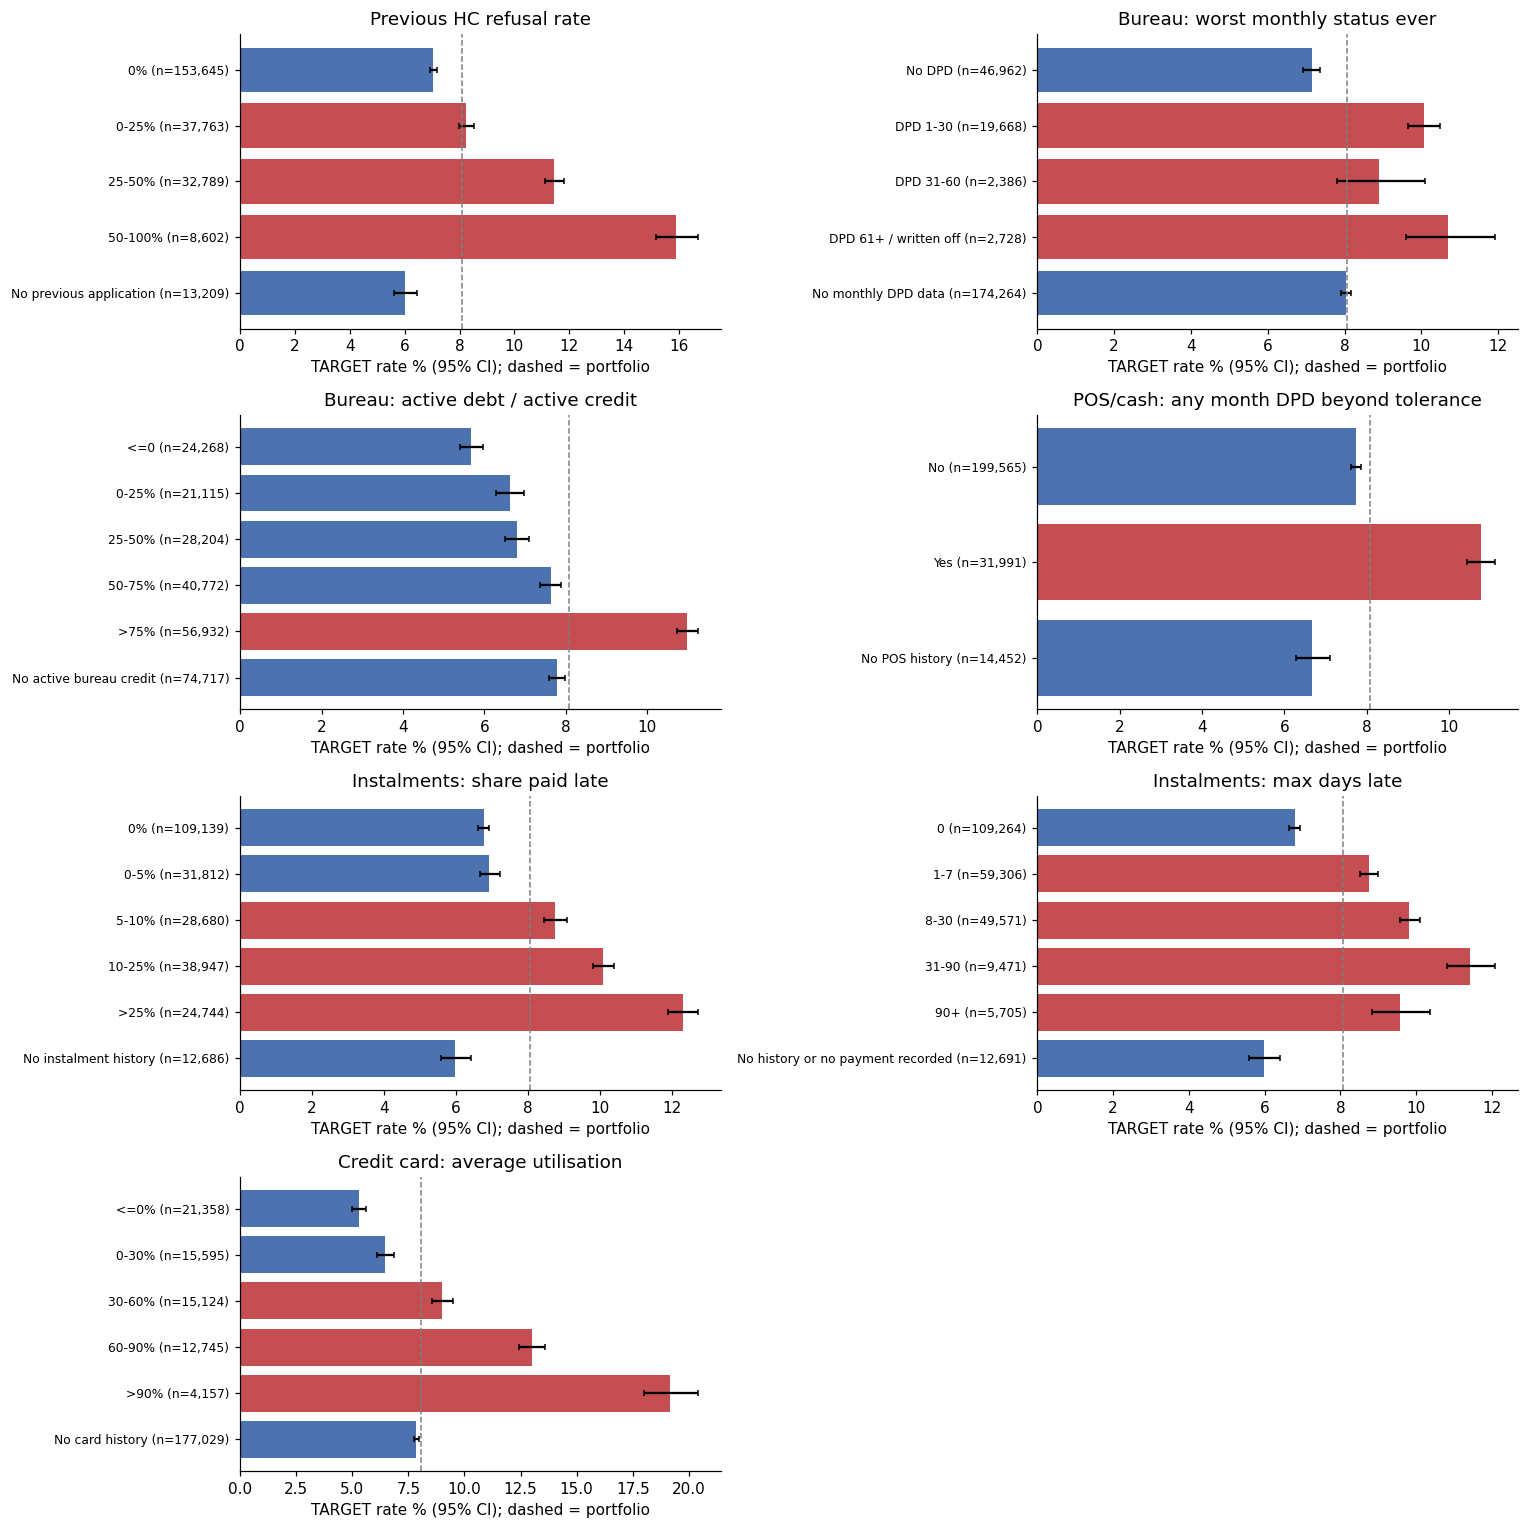


--- Previous HC refusal rate


,n,share_pct,rate_pct,ci_low,ci_high,lift
_b,,,,,,
0%,153645,62.46,7.05,6.92,7.18,0.87
0-25%,37763,15.35,8.25,7.98,8.53,1.02
25-50%,32789,13.33,11.45,11.11,11.80,1.42
50-100%,8602,3.50,15.90,15.15,16.69,1.97
No previous application,13209,5.37,6.02,5.63,6.44,0.75



--- Bureau: worst monthly status ever


,n,share_pct,rate_pct,ci_low,ci_high,lift
_b,,,,,,
No DPD,46962,19.09,7.14,6.91,7.37,0.88
DPD 1-30,19668,7.99,10.06,9.64,10.49,1.25
DPD 31-60,2386,0.97,8.89,7.81,10.09,1.10
DPD 61+ / written off,2728,1.11,10.70,9.60,11.92,1.33
No monthly DPD data,174264,70.84,8.05,7.92,8.18,1.00



--- Bureau: active debt / active credit


...

,n,share_pct,rate_pct,ci_low,ci_high,lift
_b,,,,,,
0%,109139,44.36,6.78,6.63,6.93,0.84
0-5%,31812,12.93,6.93,6.66,7.22,0.86
5-10%,28680,11.66,8.77,8.45,9.10,1.09
10-25%,38947,15.83,10.10,9.81,10.40,1.25
>25%,24744,10.06,12.32,11.91,12.73,1.53
No instalment history,12686,5.16,5.98,5.58,6.41,0.74



--- Instalments: max days late


,n,share_pct,rate_pct,ci_low,ci_high,lift
_b,,,,,,
0,109264,44.41,6.79,6.64,6.94,0.84
1-7,59306,24.11,8.75,8.52,8.98,1.08
8-30,49571,20.15,9.82,9.56,10.09,1.22
31-90,9471,3.85,11.42,10.80,12.08,1.42
90+,5705,2.32,9.57,8.83,10.36,1.19
No history or no payment recorded,12691,5.16,5.98,5.58,6.41,0.74



--- Credit card: average utilisation


,n,share_pct,rate_pct,ci_low,ci_high,lift
_b,,,,,,
<=0%,21358,8.68,5.29,4.99,5.59,0.65
0-30%,15595,6.34,6.48,6.11,6.88,0.80
30-60%,15124,6.15,9.00,8.55,9.47,1.11
60-90%,12745,5.18,13.00,12.43,13.60,1.61
>90%,4157,1.69,19.17,18.00,20.40,2.37
No card history,177029,71.96,7.85,7.73,7.98,0.97


In [33]:
def band(x, edges, labels, missing="No history"):
    out = pd.cut(x, edges, labels=labels).astype(object)
    return out.where(x.notna(), missing), labels + [missing]

hist_views = {
    "Previous HC refusal rate": band(eda.PREV_REFUSAL_RATE, [-.01, 0, .25, .5, 1],
                                     ["0%", "0-25%", "25-50%", "50-100%"], "No previous application"),
    "Bureau: worst monthly status ever": band(eda.BUREAU_WORST_STATUS, [-1, 0, 1, 2, 5],
                                              ["No DPD", "DPD 1-30", "DPD 31-60", "DPD 61+ / written off"],
                                              "No monthly DPD data"),
    "Bureau: active debt / active credit": band(eda.BUREAU_ACTIVE_DEBT_RATIO, [-1.01, 0, .25, .5, .75, 5],
                                                ["<=0", "0-25%", "25-50%", "50-75%", ">75%"], "No active bureau credit"),
    "POS/cash: any month DPD beyond tolerance": band(eda.POS_ANY_DPD_DEF, [-1, 0, 1], ["No", "Yes"], "No POS history"),
    "Instalments: share paid late": band(eda.INST_SHARE_LATE, [-.01, 0, .05, .1, .25, 1],
                                         ["0%", "0-5%", "5-10%", "10-25%", ">25%"], "No instalment history"),
    "Instalments: max days late": band(eda.INST_MAX_DAYS_LATE, [-1, 0, 7, 30, 90, 1e5],
                                       ["0", "1-7", "8-30", "31-90", "90+"], "No history or no payment recorded"),
    "Credit card: average utilisation": band(eda.CC_AVG_UTILISATION, [-1.01, 0, .3, .6, .9, 3],
                                             ["<=0%", "0-30%", "30-60%", "60-90%", ">90%"], "No card history"),
}
hist_tables = {}
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
for ax, (name, (s, order)) in zip(axes.ravel(), hist_views.items()):
    hist_tables[name] = t = rate_table(eda.assign(_b=s), "_b", min_n=100, order=order)
    plot_rates(t, ax, name)
axes.ravel()[-1].axis("off")
plt.tight_layout(); fig.savefig(FIG / "03_history_risk.png", bbox_inches="tight"); plt.show()
for name, t in hist_tables.items():
    print(f"\n--- {name}"); display(t[["n", "share_pct", "rate_pct", "ci_low", "ci_high", "lift"]])

**Findings.**
* **Card utilisation is the strongest history signal.** Risk rises steadily from 5.29% (no balance) to 19.17% above 90%
  utilisation, a 2.4× lift. It only covers the 28% of applicants with a Home Credit card.
* **Prior refusals.** Rates grow from 7.05% (never refused) to 15.90% when half or more of previous applications were refused.
* **Bureau debt load.** Applicants who still owe more than 75% of their active credit run at 10.98%, versus 5.67% when nothing is outstanding.
* **Repayment discipline.** The share of late instalments rises from 6.78% (none late) to 12.32% (more than 25% late). Any POS
  delinquency goes with 10.78% versus 7.74%.
* **Severity is non-monotonic.** Maximum lateness peaks at 31–90 days (11.42%) and *drops* for 90+ days (9.57%). Bureau worst
  status is similar: DPD 31–60 at 8.89% sits below DPD 1–30 at 10.06%, with wide intervals, and 70.84% of applicants have no
  bureau monthly data. One hypothesis is that old, resolved delinquencies matter less than recent ones; recency-weighted
  features will test this in Step 5.
* **"No history" is not riskier here.** Applicants without previous applications (6.02%), instalment history (5.98%) or POS
  history (6.68%) are *below* the portfolio rate. This may reflect stricter acceptance of new clients (selection), so it should
  not be read as "thin-file applicants are safe".

**Decisions.**
* Build explicit has-history flags, and never impute missing history as zero.
* Engineer recency-windowed versions (for example the last 12 months) of the delinquency and utilisation features in Step 5.
* Card utilisation and repayment behaviour are the most actionable inputs for underwriting policy.

### 10.6 Which variables rank risk best on their own?
Single-feature ROC-AUC is computed on the rows where the feature exists (coverage is shown) and oriented to be ≥ 0.5.
Direction "+" means higher values go with higher risk. AVG/MODE/MEDI building triplets are represented by their AVG version.

,feature,auc,direction,fold_auc_std,coverage_pct,source
0,EXT_SOURCE_3,0.6797,-,0.0047,80.1612,application
1,EXT_SOURCE_1,0.6659,-,0.0038,43.6624,application
2,EXT_SOURCE_2,0.6553,-,0.0052,99.7842,application
3,CC_AVG_UTILISATION,0.6306,+,0.0060,28.0393,history
4,CC_MAX_UTILISATION,0.6108,+,0.0036,28.0393,history
5,AGE_YEARS,0.5843,-,0.0019,100.0000,engineered
6,EMPLOYED_YEARS,0.5823,-,0.0023,82.0563,engineered
7,BUREAU_ACTIVE_DEBT_RATIO,0.5796,+,0.0035,69.6282,history
8,CREDIT_TO_GOODS,0.5679,+,0.0042,99.9102,engineered
9,INST_SHARE_LATE,0.5656,+,0.0050,94.8433,history


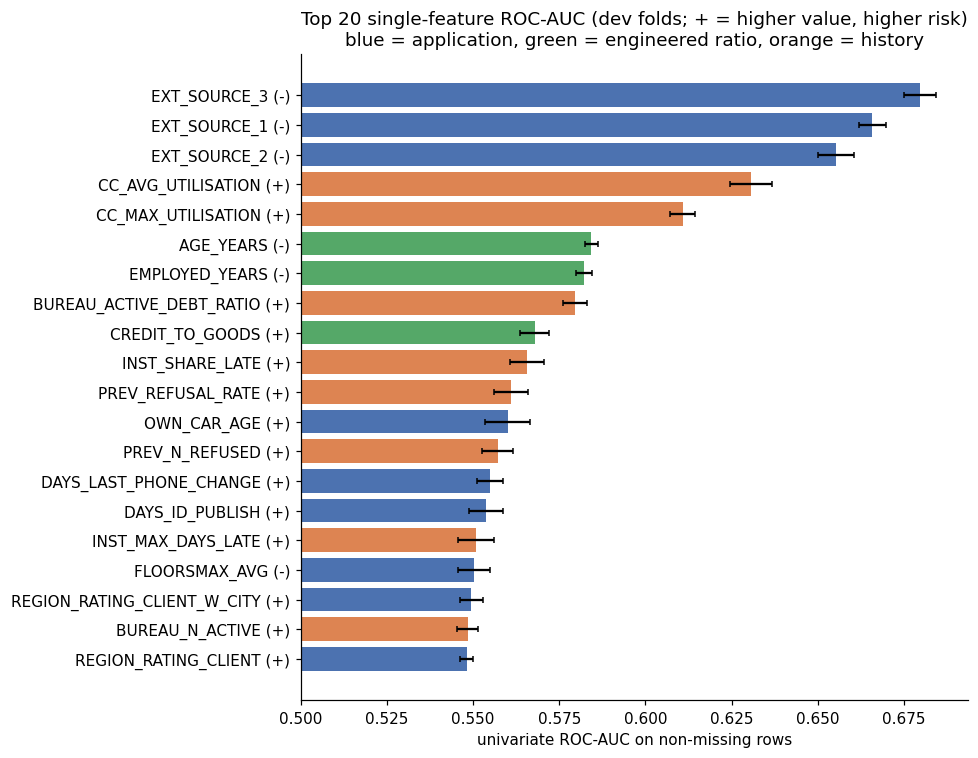

Max fold-to-fold std among top 20: 0.0066


In [34]:
# Univariate ranking power with stability across the 5 development folds
cand = (eda.select_dtypes("number").columns
        .drop(["SK_ID_CURR", "TARGET", "fold", "DAYS_BIRTH", "DAYS_EMPLOYED"], errors="ignore"))  # duplicates of AGE/EMPLOYED_YEARS
cand = [c for c in cand if not c.endswith(("_MODE", "_MEDI")) and not c.startswith("FLAG_DOCUMENT")]
rows = []
for c in cand:
    a, d = univariate_auc(eda[c], eda.TARGET)
    if np.isnan(a):
        continue
    fold_auc = [univariate_auc(eda.loc[eda.fold == k, c], eda.loc[eda.fold == k, "TARGET"])[0] for k in range(5)]
    rows.append({"feature": c, "auc": a, "direction": d, "fold_auc_std": np.nanstd(fold_auc),
                 "coverage_pct": 100 * eda[c].notna().mean(),
                 "source": "history" if c in hist.columns else ("engineered" if c in
                           {"CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "CREDIT_TO_GOODS", "CREDIT_TERM_MONTHS",
                            "AGE_YEARS", "EMPLOYED_YEARS", "NOT_EMPLOYED"} else "application")})
drivers = pd.DataFrame(rows).sort_values("auc", ascending=False).reset_index(drop=True).round(4)
drivers.to_csv(REPORTS / "eda_univariate_auc.csv", index=False)
display(drivers.head(25))

top = drivers.head(20).iloc[::-1]
colors = top.source.map({"application": "#4C72B0", "engineered": "#55A868", "history": "#DD8452"})
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.feature + " (" + top.direction + ")", top.auc - .5, left=.5, color=colors,
        xerr=top.fold_auc_std, capsize=2)
ax.axvline(.5, c="grey", lw=1)
ax.set(title="Top 20 single-feature ROC-AUC (dev folds; + = higher value, higher risk)\n"
             "blue = application, green = engineered ratio, orange = history",
       xlabel="univariate ROC-AUC on non-missing rows")
plt.tight_layout(); fig.savefig(FIG / "03_univariate_drivers.png", bbox_inches="tight"); plt.show()
print("Max fold-to-fold std among top 20:", top.fold_auc_std.max())

**Findings.**
* The three external scores lead (AUC 0.680, 0.666 and 0.655), followed by card utilisation (0.631, for 28% of applicants),
  age (0.584), employment length (0.582) and bureau active debt ratio (0.580).
* History-based indicators make up 8 of the top 20, so the extra tables add real information beyond the application form.
* The fold-to-fold standard deviation is at most 0.0066 across the top 20, so these rankings are stable.
* Every single feature is weak on its own (all AUC < 0.70). Useful discrimination must come from combining many signals, which
  supports a multivariate model rather than a few hard rules.
* Single-feature AUC only captures **monotonic** ranking. Non-monotonic signals such as implied term (Section 10.3) are
  under-rated here and are better captured by trees or binning.

### 10.7 Redundant variables

In [35]:
num_app = [c if c != "DAYS_EMPLOYED" else "DAYS_EMPLOYED" for c in APP_NUMERIC]
sample = eda[num_app].sample(60_000, random_state=SEED)
corr = sample.corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename("rho").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
high = pairs[pairs.rho.abs() >= 0.90].sort_values("rho", key=abs, ascending=False)
is_building = lambda s: s.str.endswith(("_AVG", "_MODE", "_MEDI"))
print(f"Numeric application columns: {len(num_app)} | pairs with |rho| >= 0.90: {len(high)} "
      f"(of which both building columns: {(is_building(high.a) & is_building(high.b)).sum()})")
display(high[~(is_building(high.a) & is_building(high.b))].round(3))

Numeric application columns: 104 | pairs with |rho| >= 0.90: 71 (of which both building columns: 68)


,a,b,rho
7667,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.998
212,AMT_CREDIT,AMT_GOODS_PRICE,0.985
1891,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,0.951


**Findings.** Of the 104 numeric application columns, 71 pairs have |Spearman ρ| ≥ 0.90. 68 of these are within the building
block, where 14 attributes are each stored as AVG, MODE and MEDI. The other three pairs are:
* 30- and 60-day social-circle observation counts (ρ = 0.998);
* credit amount and goods price (ρ = 0.985), whose information is better carried by the credit-to-goods ratio;
* the two regional rating variables (ρ = 0.951).

**Decisions (finalised in Step 4 with variance inflation factors).**
* For Logistic Regression: keep the AVG building columns and drop MODE/MEDI, and keep one member of each other redundant pair.
* Tree models tolerate redundancy, but fewer duplicates make importance scores easier to interpret.

### 10.8 EDA synthesis: findings that drive later decisions

| # | Finding (development data) | Credit-risk implication | Decision |
|---|---|---|---|
| 1 | External scores are the strongest signals (6–7× decile spread) but have undocumented provenance | High predictive value with vendor and drift risk | Use and monitor; evaluate a model without them (Step 9) |
| 2 | Card utilisation > 90% → 19.17% vs 5.29% at zero balance | Revolving-credit stress is the clearest behavioural warning sign | Core feature; candidate for verification or limit policy |
| 3 | Prior refusals, bureau debt load and late instalments all raise risk monotonically | Past behaviour adds information beyond the application form | Full history aggregation in Step 5, with recency windows |
| 4 | Severity of past delinquency is non-monotonic | Recency likely matters more than worst-ever status | Time-windowed and recency-weighted features |
| 5 | Credit-to-income is not monotonic; credit-to-goods and implied term are non-linear | Simple affordability cut-offs would mis-target risk | Tree model plus binned features for Logistic Regression; no hard income-ratio rule |
| 6 | Age and employment length fall monotonically with risk | Stable, interpretable drivers | Linear terms; compliance review for age |
| 7 | Gender shows a gap (10.14% vs 7.00%) | Sensitive attribute | Excluded from inputs by default; used in the Step 11 fairness check |
| 8 | Applicants without history are below average risk | Likely selection, not genuine safety | Has-history flags; no zero imputation |
| 9 | 71 highly correlated pairs, mostly building triplets | Redundancy inflates Logistic Regression variance and blurs importance | Reduce in Step 4 |
| 10 | All single features have AUC < 0.70, with stable rankings | No single rule separates risk well | Multivariate modelling with cost-based thresholds |

**Stage status.** Step 3 is complete. The next stage is **Step 4 — data cleaning and preprocessing pipeline**.